In [1]:
import os
import re  
import math
import pickle
import zipfile
from collections import defaultdict

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  

import h5py
from scipy import signal
from scipy.stats import (zscore, ks_2samp, linregress, pearsonr)
from scipy.signal import (convolve, windows, resample)
from scipy.ndimage import gaussian_filter1d

from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import (PolynomialFeatures, StandardScaler)
from sklearn.model_selection import (train_test_split, cross_val_score, KFold)
from sklearn.metrics import r2_score, mean_squared_error
import umap.umap_ as umap

from scipy.signal import convolve, windows
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from pyglmnet import GLM

/Users/nmt121/Desktop/Repositories/Motoneuron_Model/.conda/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [281]:
from functions_experimental_data_Bräckleinexp import *

# def conv_spikes(array, pos1, pos2, fs, window_duration=0.3):
#     window_samples = int(round(window_duration * fs))
#     hanning_window = windows.hann(window_samples)
#     hanning_window /= np.sum(hanning_window)  
#     smoothed_spike_array1 = convolve(array[pos1, :], hanning_window, mode='same') * fs
#     smoothed_spike_array2 = convolve(array[pos2, :], hanning_window, mode='same') * fs
#     return smoothed_spike_array1, smoothed_spike_array2

Fsamp = 2048  # Sampling frequency


## firing rates

In [282]:
folder_path = '/Users/nmt121/Desktop/DATA/S1'

pkl_files = sorted([f for f in os.listdir(folder_path) if f.endswith('.pkl')], key=lambda x: (extract_day(x), extract_trial(x)))

plot_firing_rates(folder_path, pkl_files, Fsamp)


NameError: name 'plot_firing_rates' is not defined

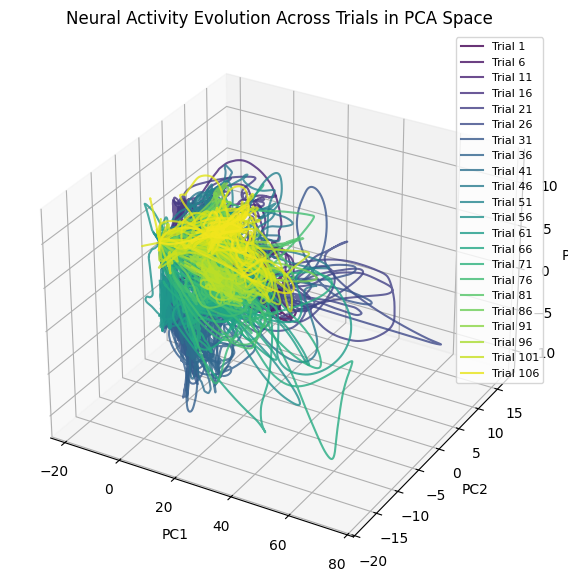

In [337]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D
from scipy.signal import resample
from scipy.signal import convolve, windows


folder_path = '/Users/nmt121/Desktop/DATA/S3'
pkl_files = sorted(
    [f for f in os.listdir(folder_path) if f.endswith('.pkl')],
    key=lambda x: (extract_day(x), extract_trial(x))
)

# === Function to Compute Smoothed Firing Rates ===
def compute_firing_rates(spike_array, fs, window_duration=0.5):
    window_samples = int(round(window_duration * fs))  # Convert duration to samples
    hanning_window = windows.hann(window_samples)  # Create Hanning window
    hanning_window /= np.sum(hanning_window)  # Normalize window
    
    smoothed_firing_rates = np.zeros_like(spike_array, dtype=float)
    
    for i in range(spike_array.shape[0]):  
        smoothed_firing_rates[i, :] = convolve(spike_array[i, :], hanning_window, mode='same') * fs  
    
    return smoothed_firing_rates

# === Function to Apply PCA on Smoothed Firing Rates ===
def apply_pca_on_firing_rates(folder_path, pkl_files, fsamp=2048, n_components=5):
    all_trials = []
    trial_lengths = []
    min_neurons = float('inf')  # Find the smallest number of neurons across trials

    for file in pkl_files:
        file_path = os.path.join(folder_path, file)

        with open(file_path, 'rb') as f:
            data = pickle.load(f)

        data_MU = np.array(data['MU'].tolist())  # Extract neuron spike trains
        smoothed_firing_rates = compute_firing_rates(data_MU, fsamp)  # Compute smoothed firing rates

        min_neurons = min(min_neurons, smoothed_firing_rates.shape[0])  # Track smallest neuron count

    for file in pkl_files:
        file_path = os.path.join(folder_path, file)

        with open(file_path, 'rb') as f:
            data = pickle.load(f)

        data_MU = np.array(data['MU'].tolist())  # Extract neuron spike trains
        smoothed_firing_rates = compute_firing_rates(data_MU, fsamp)  # Compute smoothed firing rates

        # Resample neurons to match min_neurons
        if smoothed_firing_rates.shape[0] > min_neurons:
            smoothed_firing_rates = resample(smoothed_firing_rates, min_neurons, axis=0)

        # Transpose for PCA (time × neurons)
        all_trials.append(smoothed_firing_rates.T)  
        trial_lengths.append(smoothed_firing_rates.shape[1])

    # Concatenate trials along time axis (total_time × neurons)
    all_trials_matrix = np.vstack(all_trials)  # Shape: (total_time × min_neurons)

    # Apply PCA
    pca = PCA(n_components=n_components)
    transformed_data = pca.fit_transform(all_trials_matrix)  # Shape: (total_time × PCs)

    # Compute trial start indices
    trial_starts = np.cumsum([0] + trial_lengths[:-1])  # Start indices for each trial

    # Create color gradient across trials
    colormap = cm.viridis
    colors = [colormap(i / len(pkl_files)) for i in range(len(pkl_files))]

    # Plot PCA evolution over trials
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')

    for idx in range(len(trial_starts) - 1):
        start, end = trial_starts[idx], trial_starts[idx + 1]
        ax.plot(transformed_data[start:end, 0], transformed_data[start:end, 1], transformed_data[start:end, 2], 
                color=colors[idx], alpha=0.8, label=f'Trial {idx+1}')

    # Labels and title
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    ax.set_title("Neural Activity Evolution Across Trials in PCA Space")

    # Improve legend clarity (show every 5th trial)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::5], labels[::5], loc='best', fontsize=8)  

    plt.show()

# === Run PCA on Smoothed Firing Rates ===
apply_pca_on_firing_rates(folder_path, pkl_files, Fsamp)


In [879]:
# === PARAMETERS ===
folder_path = '/Users/nmt121/Desktop/DATA/S4'

pkl_files = sorted([f for f in os.listdir(folder_path) if f.endswith('.pkl')])
pkl_files

['E3_MB04_Day01High_16.pkl',
 'E3_MB04_Day01High_19.pkl',
 'E3_MB04_Day01High_2.pkl',
 'E3_MB04_Day01High_24.pkl',
 'E3_MB04_Day01High_26.pkl',
 'E3_MB04_Day01High_30.pkl',
 'E3_MB04_Day01High_6.pkl',
 'E3_MB04_Day01High_8.pkl',
 'E3_MB04_Day03High_10.pkl',
 'E3_MB04_Day03High_14.pkl',
 'E3_MB04_Day03High_17.pkl',
 'E3_MB04_Day03High_19.pkl',
 'E3_MB04_Day03High_22.pkl',
 'E3_MB04_Day03High_27.pkl',
 'E3_MB04_Day03High_28.pkl',
 'E3_MB04_Day03High_3.pkl',
 'E3_MB04_Day03High_5.pkl',
 'E3_MB04_Day03High_8.pkl',
 'E3_MB04_Day07High_15.pkl',
 'E3_MB04_Day07High_29.pkl',
 'E3_MB04_Day07High_6.pkl',
 'E3_MB04_Day07High_8.pkl',
 'E3_MB04_Day08High_11.pkl',
 'E3_MB04_Day08High_13.pkl',
 'E3_MB04_Day08High_18.pkl',
 'E3_MB04_Day08High_19.pkl',
 'E3_MB04_Day08High_2.pkl',
 'E3_MB04_Day08High_22.pkl',
 'E3_MB04_Day08High_27.pkl',
 'E3_MB04_Day08High_28.pkl',
 'E3_MB04_Day08High_6.pkl',
 'E3_MB04_Day08High_9.pkl',
 'E3_MB04_Day09High_1.pkl',
 'E3_MB04_Day09High_19.pkl',
 'E3_MB04_Day09High_24.pkl


🔄 Processing Trial 1: E3_MB03_Day01High_12.pkl
✅ Best alpha for Trial 1: 1
   📊 Fold 1 pR²: 0.409
   📊 Fold 2 pR²: 0.492
   📊 Fold 3 pR²: 0.509
✅ Trial 1 pR²: 0.470

🔄 Processing Trial 2: E3_MB03_Day01High_14.pkl
✅ Best alpha for Trial 2: 0.1
   📊 Fold 1 pR²: 0.596
   📊 Fold 2 pR²: 0.653
   📊 Fold 3 pR²: 0.720
✅ Trial 2 pR²: 0.656

🔄 Processing Trial 3: E3_MB03_Day01High_16.pkl
✅ Best alpha for Trial 3: 0.1
   📊 Fold 1 pR²: 0.583
   📊 Fold 2 pR²: 0.651
   📊 Fold 3 pR²: 0.509
✅ Trial 3 pR²: 0.581

🔄 Processing Trial 4: E3_MB03_Day01High_19.pkl
✅ Best alpha for Trial 4: 1
   📊 Fold 1 pR²: 0.118
   📊 Fold 2 pR²: 0.293
   📊 Fold 3 pR²: 0.198
✅ Trial 4 pR²: 0.203

🔄 Processing Trial 5: E3_MB03_Day01High_23.pkl
✅ Best alpha for Trial 5: 1
   📊 Fold 1 pR²: 0.195
   📊 Fold 2 pR²: 0.159
   📊 Fold 3 pR²: -0.088
✅ Trial 5 pR²: 0.088

🔄 Processing Trial 6: E3_MB03_Day01High_27.pkl
✅ Best alpha for Trial 6: 0.1
⚠️ Fold 1: Skipping (Too few spikes in validation set)
   📊 Fold 2 pR²: 0.491
   📊 Fold

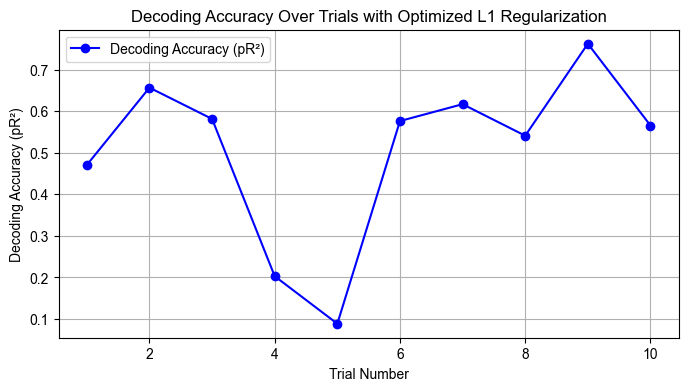

0.5059305886137775


In [908]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor
from scipy.ndimage import gaussian_filter1d

# === PARAMETERS ===
folder_path = '/Users/nmt121/Desktop/DATA/S3'
bin_size_ms = 500  
history_bins = 4

# === TRIAL FILES ===
pkl_files = [
'E3_MB03_Day01High_12.pkl',
 'E3_MB03_Day01High_14.pkl',
 'E3_MB03_Day01High_16.pkl',
 'E3_MB03_Day01High_19.pkl',
 'E3_MB03_Day01High_23.pkl',
 'E3_MB03_Day01High_27.pkl',
 'E3_MB03_Day01High_29.pkl',
 'E3_MB03_Day01High_3.pkl',
 'E3_MB03_Day01High_4.pkl',
 'E3_MB03_Day01High_8.pkl',


]



# === HYPERPARAMETER GRID (Avoid extreme alpha values) ===
alpha_grid = {'alpha': [0.1, 1, 10]}  

def load_and_preprocess(file, bin_size_ms):
    """Load a single trial and preprocess."""
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f:
        data = pickle.load(f)
    
    data_MU = np.array(data['MU'].tolist())  
    binned_spikes = np.add.reduceat(data_MU, np.arange(0, data_MU.shape[1], bin_size_ms), axis=1)
    smoothed_spikes = gaussian_filter1d(binned_spikes, sigma=1, axis=1)  

    return smoothed_spikes.T, data

def create_glm_data(spike_data, history_bins, target_idx):
    """Create X (predictors) and Y (target) for GLM while ignoring neurons that never spike."""
    num_timebins, num_neurons = spike_data.shape
    
    # Identify neurons that spike more than 10 times
    active_neurons = np.where(spike_data.sum(axis=0) > 10)[0]
    
    if target_idx not in active_neurons:
        return None, None  # If the target neuron is inactive, return None to skip trial
    
    X_list, Y_list = [], []
    
    for t in range(history_bins, num_timebins):
        # Exclude neurons that never spike + target neuron itself from predictors
        X_t = np.hstack([
            spike_data[t - h, np.logical_and(
                np.arange(num_neurons) != target_idx,  
                np.isin(np.arange(num_neurons), active_neurons)
            )]
            for h in range(1, history_bins + 1)
        ])
        Y_t = spike_data[t, target_idx]  
        X_list.append(X_t)
        Y_list.append(Y_t)
    
    return np.array(X_list), np.array(Y_list)

def compute_pR2(model, X, Y):
    """Compute McFadden's pseudo-R² with improved numerical stability."""
    y_pred = model.predict(X)

    # Prevent log(0) errors by ensuring positive values
    y_pred = np.clip(y_pred, 1e-6, None)  
    Y = np.clip(Y, 1e-6, None)  

    # Prevent errors when all spikes are 0
    if np.all(Y == 0) or np.all(y_pred == 0):
        return np.nan  # Skip computation if no meaningful prediction is possible
    
    deviance_model = 2 * np.sum(Y * np.log(Y / y_pred) - (Y - y_pred))  
    deviance_null = 2 * np.sum(Y * np.log(Y / np.mean(Y)) - (Y - np.mean(Y)))

    # Handle division by zero
    if deviance_null == 0 or np.isnan(deviance_null):
        return np.nan  # Skip invalid computations

    return 1 - (deviance_model / deviance_null)

# === STORE RESULTS ===
trial_pR2_scores = []  # Stores pR² for each trial

# === LOOP THROUGH EACH TRIAL ===
for trial_idx, file in enumerate(pkl_files):
    print(f"\n🔄 Processing Trial {trial_idx + 1}: {file}")

    # Load and preprocess trial data
    glm_data,data = load_and_preprocess(file, bin_size_ms)

    # Target neuron selection
    target_idx = 1#data['Idx_MU_Pair'].tolist()[1]
    
    # Create design matrix (X) and target (Y), ignoring neurons that never spike
    X, Y = create_glm_data(glm_data, history_bins, target_idx)
    
    if X is None or Y is None:
        print(f"⚠️ Trial {trial_idx + 1}: Target neuron inactive or no valid neurons left, skipping")
        trial_pR2_scores.append(np.nan)
        continue  # Skip trial if target neuron is not present

    X[np.isnan(X)] = 0  

    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # === HYPERPARAMETER TUNING (Grid Search for Best Alpha) ===
    kf = KFold(n_splits=3, shuffle=True, random_state=42)
    poisson_cv = GridSearchCV(PoissonRegressor(max_iter=1000), alpha_grid, cv=kf, scoring='neg_mean_poisson_deviance')
    poisson_cv.fit(X_scaled, Y)

    best_alpha = poisson_cv.best_params_['alpha']
    print(f"✅ Best alpha for Trial {trial_idx + 1}: {best_alpha}")

    # === CROSS-VALIDATION FOR THIS TRIAL ===
    trial_pR2 = []

    for fold_idx, (train_idx, val_idx) in enumerate(kf.split(X_scaled, Y > 0)):
        X_train_cv, X_val_cv = X_scaled[train_idx], X_scaled[val_idx]
        Y_train_cv, Y_val_cv = Y[train_idx], Y[val_idx]

        # Skip fold if too few spikes
        if np.sum(Y_val_cv) < 5:
            print(f"⚠️ Fold {fold_idx + 1}: Skipping (Too few spikes in validation set)")
            continue  

        # Train Poisson model with best alpha
        poisson_model_cv = PoissonRegressor(alpha=best_alpha, max_iter=1000)
        poisson_model_cv.fit(X_train_cv, Y_train_cv)

        # Compute pseudo-R²
        pR2_value = compute_pR2(poisson_model_cv, X_val_cv, Y_val_cv)
        trial_pR2.append(pR2_value)

        print(f"   📊 Fold {fold_idx + 1} pR²: {pR2_value:.3f}")

    # Compute mean pR² for this trial
    mean_trial_pR2 = np.nanmean(trial_pR2) if len(trial_pR2) > 0 else np.nan
    trial_pR2_scores.append(mean_trial_pR2)

    print(f"✅ Trial {trial_idx + 1} pR²: {mean_trial_pR2:.3f}")

# === PLOT DECODING ACCURACY OVER TRIALS ===
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(pkl_files) + 1), trial_pR2_scores, 'bo-', markersize=6, label="Decoding Accuracy (pR²)")
plt.xlabel("Trial Number")
plt.ylabel("Decoding Accuracy (pR²)")
plt.title("Decoding Accuracy Over Trials with Optimized L1 Regularization")
plt.legend()
plt.grid(True)
plt.show()

print(np.nanmean(trial_pR2_scores))



🔄 Processing Trial 1: E3_MB04_Day01High_2.pkl

🔄 Processing Trial 2: E3_MB04_Day01High_6.pkl

🔄 Processing Trial 3: E3_MB04_Day01High_8.pkl

🔄 Processing Trial 4: E3_MB04_Day01High_16.pkl

🔄 Processing Trial 5: E3_MB04_Day01High_19.pkl

🔄 Processing Trial 6: E3_MB04_Day01High_24.pkl

🔄 Processing Trial 7: E3_MB04_Day01High_26.pkl

🔄 Processing Trial 8: E3_MB04_Day01High_30.pkl


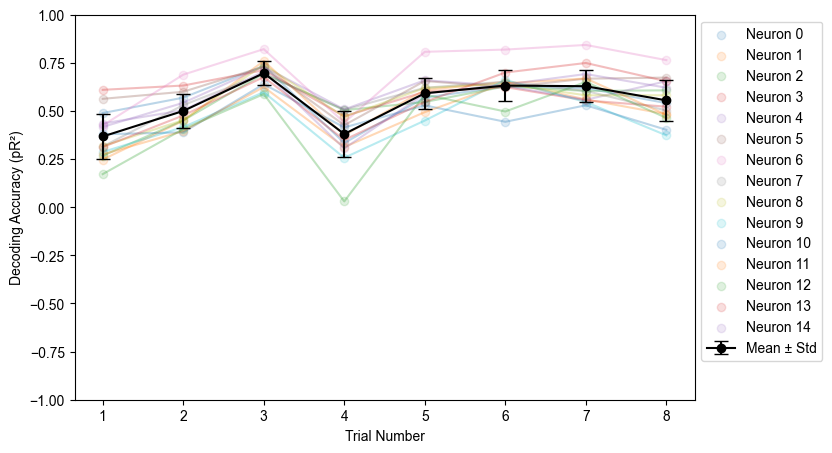

np.float64(0.5439675638211215)

In [909]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor
from scipy.ndimage import gaussian_filter1d
import re


def load_and_preprocess(file, bin_size_ms):
    """Load a single trial and preprocess."""
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f:
        data = pickle.load(f)
    
    data_MU = np.array(data['MU'].tolist())  
    binned_spikes = np.add.reduceat(data_MU, np.arange(0, data_MU.shape[1], bin_size_ms), axis=1)
    smoothed_spikes = gaussian_filter1d(binned_spikes, sigma=1, axis=1)  

    return smoothed_spikes.T, data


# === PARAMETERS ===
folder_path = '/Users/nmt121/Desktop/DATA/S1/MIXED'
folder_path = '/Users/nmt121/Desktop/DATA/S4/'

bin_size_ms = 500  
history_bins = 4

# === TRIAL FILES ===
pkl_files = [
 
'E3_MB04_Day01High_16.pkl',
 'E3_MB04_Day01High_19.pkl',
 'E3_MB04_Day01High_2.pkl',
 'E3_MB04_Day01High_24.pkl',
 'E3_MB04_Day01High_26.pkl',
 'E3_MB04_Day01High_30.pkl',
 'E3_MB04_Day01High_6.pkl',
 'E3_MB04_Day01High_8.pkl',
 


]

# === SORT FILES BY NUMERIC ORDER ===
def extract_number(filename):
    match = re.search(r'_(\d+)\.pkl$', filename)
    return int(match.group(1)) if match else float('inf')

pkl_files.sort(key=extract_number)

# === HYPERPARAMETER GRID ===
alpha_grid = {'alpha': [0.1, 1, 10, 100]}  

# === STORE RESULTS ===
results = []  

for trial_idx, file in enumerate(pkl_files):
    print(f"\n🔄 Processing Trial {trial_idx + 1}: {file}")
    glm_data, data = load_and_preprocess(file, bin_size_ms)
    
    num_neurons = glm_data.shape[1]
    for target_idx in range(num_neurons):
        X, Y = create_glm_data(glm_data, history_bins, target_idx)
        
        if X is None or Y is None or np.sum(Y) == 0:
            print(f"⚠️ Skipping neuron {target_idx} (inactive or no valid neurons left)")
            continue  

        X[np.isnan(X)] = 0  
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        
        kf = KFold(n_splits=3, shuffle=True, random_state=42)
        poisson_cv = GridSearchCV(PoissonRegressor(max_iter=1000), alpha_grid, cv=kf, scoring='neg_mean_poisson_deviance')
        poisson_cv.fit(X_scaled, Y)
        
        best_alpha = poisson_cv.best_params_['alpha']

        trial_pR2 = []
        for train_idx, val_idx in kf.split(X_scaled, Y > 0):
            X_train_cv, X_val_cv = X_scaled[train_idx], X_scaled[val_idx]
            Y_train_cv, Y_val_cv = Y[train_idx], Y[val_idx]

            if np.sum(Y_val_cv) < 5:
                continue  

            poisson_model_cv = PoissonRegressor(alpha=best_alpha, max_iter=1000)
            poisson_model_cv.fit(X_train_cv, Y_train_cv)
            pR2_value = compute_pR2(poisson_model_cv, X_val_cv, Y_val_cv)
            trial_pR2.append(pR2_value)
        
        if len(trial_pR2) > 0:
            mean_pR2 = np.nanmean(trial_pR2)
            results.append((trial_idx + 1, target_idx, mean_pR2))
        else:
            print(f"⚠️ Skipping neuron {target_idx} (No valid pR² values computed)")

# === PLOT RESULTS WITH IMPROVED VISUALIZATION ===
results = np.array(results)

# Extract unique trial numbers
trial_numbers = np.unique(results[:, 0])

# Compute mean and standard deviation for each trial number
means = []
stds = []

for trial in trial_numbers:
    mask = results[:, 0] == trial
    means.append(np.nanmean(results[mask, 2]))  # Mean pR² for the trial
    stds.append(np.nanstd(results[mask, 2]))   # Std deviation of pR²

# Scatter plot of individual neurons
plt.figure(figsize=(8, 5))
plt.rcParams.update({'font.family': 'Arial'})

for target_idx in np.unique(results[:, 1]):
    mask = results[:, 1] == target_idx
    plt.scatter(results[mask, 0], results[mask, 2], label=f'Neuron {int(target_idx)}', alpha=0.15)
    plt.plot(results[mask, 0], results[mask, 2], linestyle='-', alpha=0.3)

# Overlay mean ± std deviation
plt.errorbar(trial_numbers, means, yerr=stds, fmt='o-', color='black', capsize=5, label='Mean ± Std')

# Labels and title
plt.xlabel("Trial Number", fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontname="Arial")
plt.ylim([-1,1])
# Legend
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.grid(False)

plt.show()

np.mean(means)


🔄 Processing Trial 1: E3_MB04_Day01High_2.pkl

🔄 Processing Trial 2: E3_MB04_Day01High_6.pkl

🔄 Processing Trial 3: E3_MB04_Day01High_8.pkl

🔄 Processing Trial 4: E3_MB04_Day01High_16.pkl

🔄 Processing Trial 5: E3_MB04_Day01High_19.pkl

🔄 Processing Trial 6: E3_MB04_Day01High_24.pkl

🔄 Processing Trial 7: E3_MB04_Day01High_26.pkl

🔄 Processing Trial 8: E3_MB04_Day01High_30.pkl


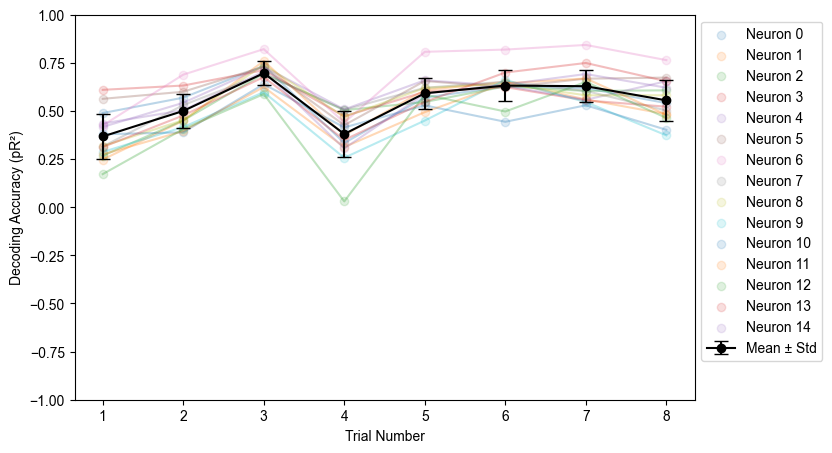

np.float64(0.5439675638211215)

In [939]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor
from scipy.ndimage import gaussian_filter1d
import re

# === PARAMETERS ===
folder_path = '/Users/nmt121/Desktop/DATA/S4/'

bin_size_ms = 500  
history_bins = 4

# === TRIAL FILES ===
pkl_files = [
'E3_MB04_Day01High_16.pkl',
 'E3_MB04_Day01High_19.pkl',
 'E3_MB04_Day01High_2.pkl',
 'E3_MB04_Day01High_24.pkl',
 'E3_MB04_Day01High_26.pkl',
 'E3_MB04_Day01High_30.pkl',
 'E3_MB04_Day01High_6.pkl',
 'E3_MB04_Day01High_8.pkl',
]

# === SORT FILES BY NUMERIC ORDER ===
def extract_number(filename):
    match = re.search(r'_(\d+)\.pkl$', filename)
    return int(match.group(1)) if match else float('inf')

pkl_files.sort(key=extract_number)

# === HYPERPARAMETER GRID ===
alpha_grid = {'alpha': [0.1, 1, 10, 100]}  

# === STORE RESULTS ===
results = []  

for trial_idx, file in enumerate(pkl_files):
    print(f"\n🔄 Processing Trial {trial_idx + 1}: {file}")
    glm_data, data = load_and_preprocess(file, bin_size_ms)
    
    num_neurons = glm_data.shape[1]
    for target_idx in range(num_neurons):
        X, Y = create_glm_data(glm_data, history_bins, target_idx)
        
        if X is None or Y is None or np.sum(Y)<20:
            print(f"⚠️ Skipping neuron {target_idx} (inactive or no valid neurons left)")
            continue  

        X[np.isnan(X)] = 0  
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        
        kf = KFold(n_splits=3, shuffle=True, random_state=42)
        poisson_cv = GridSearchCV(PoissonRegressor(max_iter=1000), alpha_grid, cv=kf, scoring='neg_mean_poisson_deviance')
        poisson_cv.fit(X_scaled, Y)
        
        best_alpha = poisson_cv.best_params_['alpha']

        trial_pR2 = []
        for train_idx, val_idx in kf.split(X_scaled, Y > 0):
            X_train_cv, X_val_cv = X_scaled[train_idx], X_scaled[val_idx]
            Y_train_cv, Y_val_cv = Y[train_idx], Y[val_idx]

            if np.sum(Y_val_cv) < 5:
                continue  

            poisson_model_cv = PoissonRegressor(alpha=best_alpha, max_iter=1000)
            poisson_model_cv.fit(X_train_cv, Y_train_cv)
            pR2_value = compute_pR2(poisson_model_cv, X_val_cv, Y_val_cv)
            trial_pR2.append(pR2_value)
        
        if len(trial_pR2) > 0:
            mean_pR2 = np.nanmean(trial_pR2)
            results.append((trial_idx + 1, target_idx, mean_pR2))
        else:
            print(f"⚠️ Skipping neuron {target_idx} (No valid pR² values computed)")

# === PLOT RESULTS WITH IMPROVED VISUALIZATION ===
results = np.array(results)

# Extract unique trial numbers
trial_numbers = np.unique(results[:, 0])

# Compute mean and standard deviation for each trial number
means = []
stds = []

for trial in trial_numbers:
    mask = results[:, 0] == trial
    means.append(np.nanmean(results[mask, 2]))  # Mean pR² for the trial
    stds.append(np.nanstd(results[mask, 2]))   # Std deviation of pR²

# Scatter plot of individual neurons
plt.figure(figsize=(8, 5))
plt.rcParams.update({'font.family': 'Arial'})

for target_idx in np.unique(results[:, 1]):
    mask = results[:, 1] == target_idx
    plt.scatter(results[mask, 0], results[mask, 2], label=f'Neuron {int(target_idx)}', alpha=0.15)
    plt.plot(results[mask, 0], results[mask, 2], linestyle='-', alpha=0.3)

# Overlay mean ± std deviation
plt.errorbar(trial_numbers, means, yerr=stds, fmt='o-', color='black', capsize=5, label='Mean ± Std')

# Labels and title
plt.xlabel("Trial Number", fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontname="Arial")
plt.ylim([-1,1])
# Legend
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.grid(False)

plt.show()

np.mean(means)

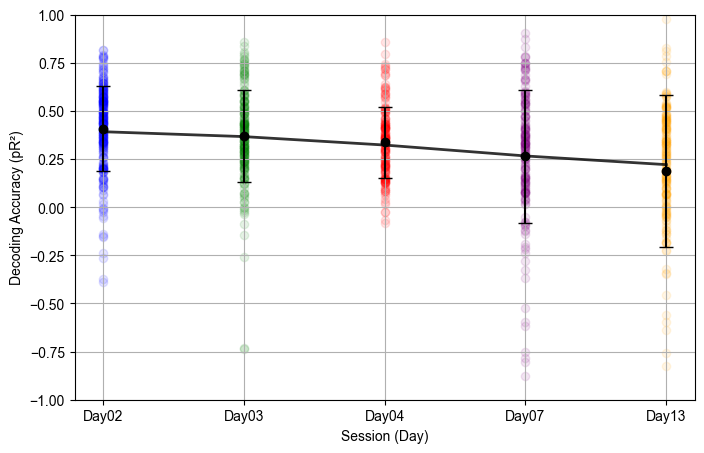

In [933]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor
from scipy.ndimage import gaussian_filter1d

# === PARAMETERS ===
folder_path = '/Users/nmt121/Desktop/DATA/S2/'

bin_size_ms = 500  
history_bins = 4

# === TRIAL FILES GROUPED BY SESSION (DAY) ===
session_files = {
    "Day02": [
        'E3_MB02_Day02High_10.pkl', 'E3_MB02_Day02High_14.pkl', 'E3_MB02_Day02High_18.pkl',
        'E3_MB02_Day02High_2.pkl', 'E3_MB02_Day02High_20.pkl', 'E3_MB02_Day02High_24.pkl',
        'E3_MB02_Day02High_27.pkl', 'E3_MB02_Day02High_29.pkl', 'E3_MB02_Day02High_6.pkl',
        'E3_MB02_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB02_Day03High_11.pkl', 'E3_MB02_Day03High_13.pkl', 'E3_MB02_Day03High_18.pkl',
        'E3_MB02_Day03High_21.pkl', 'E3_MB02_Day03High_24.pkl', 'E3_MB02_Day03High_26.pkl',
        'E3_MB02_Day03High_29.pkl', 'E3_MB02_Day03High_3.pkl', 'E3_MB02_Day03High_5.pkl',
        'E3_MB02_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB02_Day04High_11.pkl', 'E3_MB02_Day04High_14.pkl', 'E3_MB02_Day04High_16.pkl',
        'E3_MB02_Day04High_2.pkl', 'E3_MB02_Day04High_21.pkl', 'E3_MB02_Day04High_22.pkl',
        'E3_MB02_Day04High_27.pkl', 'E3_MB02_Day04High_30.pkl', 'E3_MB02_Day04High_5.pkl',
        'E3_MB02_Day04High_7.pkl'
    ],
    "Day07": [
        'E3_MB02_Day07High_1.pkl', 'E3_MB02_Day07High_12.pkl', 'E3_MB02_Day07High_13.pkl',
        'E3_MB02_Day07High_16.pkl', 'E3_MB02_Day07High_19.pkl', 'E3_MB02_Day07High_24.pkl',
        'E3_MB02_Day07High_27.pkl', 'E3_MB02_Day07High_30.pkl', 'E3_MB02_Day07High_4.pkl',
        'E3_MB02_Day07High_9.pkl'
    ],
    "Day13": [
        'E3_MB02_Day13High_1.pkl', 'E3_MB02_Day13High_11.pkl', 'E3_MB02_Day13High_13.pkl',
        'E3_MB02_Day13High_18.pkl', 'E3_MB02_Day13High_20.pkl', 'E3_MB02_Day13High_23.pkl',
        'E3_MB02_Day13High_26.pkl', 'E3_MB02_Day13High_28.pkl', 'E3_MB02_Day13High_4.pkl',
        'E3_MB02_Day13High_8.pkl'
    ]
}

# === HYPERPARAMETER GRID ===
alpha_grid = {'alpha': [0.1, 1, 10, 100]}  

# === STORE RESULTS PER SESSION ===
session_results = {}

for session, pkl_files in session_files.items():
    session_pR2 = []  # Store pR² values for the session

    for file in pkl_files:
        glm_data, data = load_and_preprocess(file, bin_size_ms)
        
        num_neurons = glm_data.shape[1]
        for target_idx in range(num_neurons):
            X, Y = create_glm_data(glm_data, history_bins, target_idx)
            
            if X is None or Y is None or np.sum(Y) <20:
                continue  

            X[np.isnan(X)] = 0  
            scaler = StandardScaler()
            X_scaled = scaler.fit_transform(X)
            
            kf = KFold(n_splits=3, shuffle=True, random_state=42)
            poisson_cv = GridSearchCV(PoissonRegressor(max_iter=1000), alpha_grid, cv=kf, scoring='neg_mean_poisson_deviance')
            poisson_cv.fit(X_scaled, Y)
            
            best_alpha = poisson_cv.best_params_['alpha']

            trial_pR2 = []
            for train_idx, val_idx in kf.split(X_scaled, Y > 0):
                X_train_cv, X_val_cv = X_scaled[train_idx], X_scaled[val_idx]
                Y_train_cv, Y_val_cv = Y[train_idx], Y[val_idx]

                if np.sum(Y_val_cv) < 5:
                    continue  

                poisson_model_cv = PoissonRegressor(alpha=best_alpha, max_iter=1000)
                poisson_model_cv.fit(X_train_cv, Y_train_cv)
                pR2_value = compute_pR2(poisson_model_cv, X_val_cv, Y_val_cv)
                trial_pR2.append(pR2_value)
            
            if len(trial_pR2) > 0:
                session_pR2.extend(trial_pR2)
    
    if len(session_pR2) > 0:
        session_results[session] = session_pR2

# === PLOT RESULTS ===
plt.figure(figsize=(8, 5))
plt.rcParams.update({'font.family': 'Arial'})

# Assign colours for sessions
session_colours = {
    "Day02": "blue",
    "Day03": "green",
    "Day04": "red",
    "Day07": "purple",
    "Day13": "orange"
}

session_means = []
session_stds = []
session_labels = []

for idx, (session, pR2_values) in enumerate(session_results.items()):
    mean_pR2 = np.nanmean(pR2_values)
    std_pR2 = np.nanstd(pR2_values)
    
    session_means.append(mean_pR2)
    session_stds.append(std_pR2)
    session_labels.append(session)

    # Scatter plot of individual neurons
    x_positions = np.full(len(pR2_values), idx)  
    plt.scatter(x_positions, pR2_values, color=session_colours[session], alpha=0.1)
    
    # Mean ± std error bars
    plt.errorbar(idx, mean_pR2, yerr=std_pR2, fmt='o', color='black', capsize=5)

# === Gaussian Smoothing of Session Means ===
x_values = np.arange(len(session_means))
smoothed_means = gaussian_filter1d(session_means, sigma=1)  # Adjust sigma for smoothness
plt.plot(x_values, smoothed_means, linestyle='-', color='black', linewidth=2, alpha=0.8)

# X-axis labels
plt.xticks(range(len(session_labels)), session_labels)

# Labels and title
plt.xlabel("Session (Day)", fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontname="Arial")
plt.ylim([-1,1])
plt.grid(True)

plt.show()


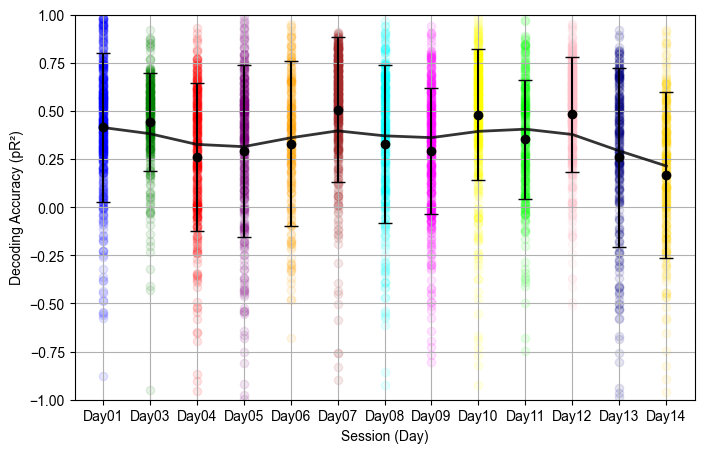

In [929]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor
from scipy.ndimage import gaussian_filter1d


def load_and_preprocess(file, bin_size_ms):
    """Load a single trial and preprocess."""
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f:
        data = pickle.load(f)
    
    data_MU = np.array(data['MU'].tolist())  
    binned_spikes = np.add.reduceat(data_MU, np.arange(0, data_MU.shape[1], bin_size_ms), axis=1)
    smoothed_spikes = gaussian_filter1d(binned_spikes, sigma=1, axis=1)  

    return smoothed_spikes.T, data


# === PARAMETERS ===
folder_path = '/Users/nmt121/Desktop/DATA/S1/'

bin_size_ms = 500  
history_bins = 4

# === TRIAL FILES GROUPED BY SESSION (DAY) ===
session_files = {
    "Day01": [
        'E3_MB01_Day01High_1.pkl', 'E3_MB01_Day01High_11.pkl', 'E3_MB01_Day01High_14.pkl',
        'E3_MB01_Day01High_17.pkl', 'E3_MB01_Day01High_21.pkl', 'E3_MB01_Day01High_24.pkl',
        'E3_MB01_Day01High_27.pkl', 'E3_MB01_Day01High_30.pkl', 'E3_MB01_Day01High_6.pkl',
        'E3_MB01_Day01High_9.pkl'
    ],
    "Day03": [
        'E3_MB01_Day03High_11.pkl', 'E3_MB01_Day03High_14.pkl', 'E3_MB01_Day03High_18.pkl',
        'E3_MB01_Day03High_21.pkl', 'E3_MB01_Day03High_23.pkl', 'E3_MB01_Day03High_26.pkl',
        'E3_MB01_Day03High_29.pkl', 'E3_MB01_Day03High_3.pkl', 'E3_MB01_Day03High_4.pkl',
        'E3_MB01_Day03High_9.pkl'
    ],
    "Day04": [
        'E3_MB01_Day04High_1.pkl', 'E3_MB01_Day04High_10.pkl', 'E3_MB01_Day04High_13.pkl',
        'E3_MB01_Day04High_17.pkl', 'E3_MB01_Day04High_20.pkl', 'E3_MB01_Day04High_23.pkl',
        'E3_MB01_Day04High_25.pkl', 'E3_MB01_Day04High_29.pkl', 'E3_MB01_Day04High_30.pkl',
        'E3_MB01_Day04High_6.pkl', 'E3_MB01_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB01_Day05High_1.pkl', 'E3_MB01_Day05High_10.pkl', 'E3_MB01_Day05High_13.pkl',
        'E3_MB01_Day05High_18.pkl', 'E3_MB01_Day05High_21.pkl', 'E3_MB01_Day05High_23.pkl',
        'E3_MB01_Day05High_26.pkl', 'E3_MB01_Day05High_28.pkl', 'E3_MB01_Day05High_5.pkl',
        'E3_MB01_Day05High_9.pkl'
    ],
    "Day06": [
        'E3_MB01_Day06High_10.pkl', 'E3_MB01_Day06High_14.pkl', 'E3_MB01_Day06High_18.pkl',
        'E3_MB01_Day06High_21.pkl', 'E3_MB01_Day06High_22.pkl', 'E3_MB01_Day06High_26.pkl',
        'E3_MB01_Day06High_3.pkl', 'E3_MB01_Day06High_30.pkl', 'E3_MB01_Day06High_5.pkl',
        'E3_MB01_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB01_Day07High_1.pkl', 'E3_MB01_Day07High_10.pkl', 'E3_MB01_Day07High_14.pkl',
        'E3_MB01_Day07High_18.pkl', 'E3_MB01_Day07High_19.pkl', 'E3_MB01_Day07High_23.pkl',
        'E3_MB01_Day07High_26.pkl', 'E3_MB01_Day07High_28.pkl', 'E3_MB01_Day07High_5.pkl',
        'E3_MB01_Day07High_9.pkl'
        
    ],
    
    "Day08": ['E3_MB01_Day08High_12.pkl', 'E3_MB01_Day08High_13.pkl', 'E3_MB01_Day08High_17.pkl',
              'E3_MB01_Day08High_21.pkl', 'E3_MB01_Day08High_23.pkl', 'E3_MB01_Day08High_25.pkl',
              'E3_MB01_Day08High_3.pkl', 'E3_MB01_Day08High_30.pkl', 'E3_MB01_Day08High_7.pkl'],
    "Day09": ['E3_MB01_Day09High_1.pkl', 'E3_MB01_Day09High_13.pkl', 'E3_MB01_Day09High_15.pkl',
              'E3_MB01_Day09High_18.pkl', 'E3_MB01_Day09High_23.pkl', 'E3_MB01_Day09High_26.pkl',
              'E3_MB01_Day09High_27.pkl', 'E3_MB01_Day09High_4.pkl', 'E3_MB01_Day09High_8.pkl',
              'E3_MB01_Day09High_9.pkl'],
    "Day10": ['E3_MB01_Day10High_1.pkl', 'E3_MB01_Day10High_10.pkl', 'E3_MB01_Day10High_15.pkl',
              'E3_MB01_Day10High_18.pkl', 'E3_MB01_Day10High_19.pkl', 'E3_MB01_Day10High_22.pkl',
              'E3_MB01_Day10High_25.pkl', 'E3_MB01_Day10High_30.pkl', 'E3_MB01_Day10High_5.pkl',
              'E3_MB01_Day10High_7.pkl'],
    "Day11": ['E3_MB01_Day11High_12.pkl', 'E3_MB01_Day11High_15.pkl', 'E3_MB01_Day11High_18.pkl',
              'E3_MB01_Day11High_20.pkl', 'E3_MB01_Day11High_24.pkl', 'E3_MB01_Day11High_25.pkl',
              'E3_MB01_Day11High_28.pkl', 'E3_MB01_Day11High_3.pkl', 'E3_MB01_Day11High_4.pkl',
              'E3_MB01_Day11High_8.pkl'],
    "Day12": ['E3_MB01_Day12High_12.pkl', 'E3_MB01_Day12High_15.pkl', 'E3_MB01_Day12High_17.pkl',
              'E3_MB01_Day12High_2.pkl', 'E3_MB01_Day12High_20.pkl', 'E3_MB01_Day12High_24.pkl',
              'E3_MB01_Day12High_25.pkl', 'E3_MB01_Day12High_28.pkl', 'E3_MB01_Day12High_4.pkl',
              'E3_MB01_Day12High_7.pkl'],
    "Day13": ['E3_MB01_Day13High_1.pkl', 'E3_MB01_Day13High_12.pkl', 'E3_MB01_Day13High_14.pkl',
              'E3_MB01_Day13High_16.pkl', 'E3_MB01_Day13High_19.pkl', 'E3_MB01_Day13High_23.pkl',
              'E3_MB01_Day13High_25.pkl', 'E3_MB01_Day13High_30.pkl', 'E3_MB01_Day13High_5.pkl',
              'E3_MB01_Day13High_9.pkl'],
    "Day14": ['E3_MB01_Day14High_12.pkl', 'E3_MB01_Day14High_15.pkl', 'E3_MB01_Day14High_18.pkl',
              'E3_MB01_Day14High_19.pkl', 'E3_MB01_Day14High_22.pkl', 'E3_MB01_Day14High_26.pkl',
              'E3_MB01_Day14High_28.pkl', 'E3_MB01_Day14High_3.pkl', 'E3_MB01_Day14High_5.pkl',
              'E3_MB01_Day14High_8.pkl']

}

# === HYPERPARAMETER GRID ===
alpha_grid = {'alpha': [0.1, 1, 10, 100]}  

# === STORE RESULTS PER SESSION ===
session_results = {}

for session, pkl_files in session_files.items():
    session_pR2 = []  # Store pR² values for the session

    for file in pkl_files:
        glm_data, data = load_and_preprocess(file, bin_size_ms)
        
        num_neurons = glm_data.shape[1]
        for target_idx in range(num_neurons):
            X, Y = create_glm_data(glm_data, history_bins, target_idx)
            
            if X is None or Y is None or np.sum(Y) <20:
                continue  

            X[np.isnan(X)] = 0  
            scaler = StandardScaler()
            X_scaled = scaler.fit_transform(X)
            
            kf = KFold(n_splits=3, shuffle=True, random_state=42)
            poisson_cv = GridSearchCV(PoissonRegressor(max_iter=1000), alpha_grid, cv=kf, scoring='neg_mean_poisson_deviance')
            poisson_cv.fit(X_scaled, Y)
            
            best_alpha = poisson_cv.best_params_['alpha']

            trial_pR2 = []
            for train_idx, val_idx in kf.split(X_scaled, Y > 0):
                X_train_cv, X_val_cv = X_scaled[train_idx], X_scaled[val_idx]
                Y_train_cv, Y_val_cv = Y[train_idx], Y[val_idx]

                if np.sum(Y_val_cv) < 5:
                    continue  

                poisson_model_cv = PoissonRegressor(alpha=best_alpha, max_iter=1000)
                poisson_model_cv.fit(X_train_cv, Y_train_cv)
                pR2_value = compute_pR2(poisson_model_cv, X_val_cv, Y_val_cv)
                trial_pR2.append(pR2_value)
            
            if len(trial_pR2) > 0:
                session_pR2.extend(trial_pR2)
    
    if len(session_pR2) > 0:
        session_results[session] = session_pR2

# === PLOT RESULTS ===
plt.figure(figsize=(8, 5))
plt.rcParams.update({'font.family': 'Arial'})

# Assign colours for sessions
session_colours = {
    "Day01": "blue",
    "Day03": "green",
    "Day04": "red",
    "Day05": "purple",
    "Day06": "orange",
    "Day07": "brown",
    "Day08": "cyan",
    "Day09": "magenta",
    "Day10": "yellow",
    "Day11": "lime",
    "Day12": "pink",
    "Day13": "navy",
    "Day14": "gold"
}

session_means = []
session_stds = []
session_labels = []

for idx, (session, pR2_values) in enumerate(session_results.items()):
    mean_pR2 = np.nanmean(pR2_values)
    std_pR2 = np.nanstd(pR2_values)
    
    session_means.append(mean_pR2)
    session_stds.append(std_pR2)
    session_labels.append(session)

    # Scatter plot of individual neurons
    x_positions = np.full(len(pR2_values), idx)  
    plt.scatter(x_positions, pR2_values, color=session_colours[session], alpha=0.1)
    
    # Mean ± std error bars
    plt.errorbar(idx, mean_pR2, yerr=std_pR2, fmt='o', color='black', capsize=5)

# === Gaussian Smoothing of Session Means ===
x_values = np.arange(len(session_means))
smoothed_means = gaussian_filter1d(session_means, sigma=1)
plt.plot(x_values, smoothed_means, linestyle='-', color='black', linewidth=2, alpha=0.8)

# X-axis labels
plt.xticks(range(len(session_labels)), session_labels)

# Labels and title
plt.xlabel("Session (Day)", fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontname="Arial")
plt.ylim([-1,1])
plt.grid(True)

plt.show()


In [ ]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor
from scipy.ndimage import gaussian_filter1d

# === PARAMETERS ===
folder_path = '/Users/nmt121/Desktop/DATA/S3/'

bin_size_ms = 500  
history_bins = 4

# === TRIAL FILES GROUPED BY SESSION (DAY) ===
session_files = {
    "Day01": ['E3_MB03_Day01High_12.pkl', 'E3_MB03_Day01High_14.pkl', 'E3_MB03_Day01High_16.pkl',
              'E3_MB03_Day01High_19.pkl', 'E3_MB03_Day01High_23.pkl', 'E3_MB03_Day01High_27.pkl',
              'E3_MB03_Day01High_29.pkl', 'E3_MB03_Day01High_3.pkl', 'E3_MB03_Day01High_4.pkl',
              'E3_MB03_Day01High_8.pkl'],
    "Day02": ['E3_MB03_Day02High_12.pkl', 'E3_MB03_Day02High_15.pkl', 'E3_MB03_Day02High_17.pkl',
              'E3_MB03_Day02High_19.pkl', 'E3_MB03_Day02High_2.pkl', 'E3_MB03_Day02High_24.pkl',
              'E3_MB03_Day02High_26.pkl', 'E3_MB03_Day02High_29.pkl', 'E3_MB03_Day02High_6.pkl',
              'E3_MB03_Day02High_8.pkl'],
    "Day03": ['E3_MB03_Day03High_10.pkl', 'E3_MB03_Day03High_15.pkl', 'E3_MB03_Day03High_17.pkl',
              'E3_MB03_Day03High_2.pkl', 'E3_MB03_Day03High_21.pkl', 'E3_MB03_Day03High_23.pkl',
              'E3_MB03_Day03High_26.pkl', 'E3_MB03_Day03High_29.pkl', 'E3_MB03_Day03High_5.pkl',
              'E3_MB03_Day03High_9.pkl'],
    "Day04": ['E3_MB03_Day04High_1.pkl', 'E3_MB03_Day04High_11.pkl', 'E3_MB03_Day04High_15.pkl',
              'E3_MB03_Day04High_16.pkl', 'E3_MB03_Day04High_20.pkl', 'E3_MB03_Day04High_23.pkl',
              'E3_MB03_Day04High_26.pkl', 'E3_MB03_Day04High_28.pkl', 'E3_MB03_Day04High_4.pkl',
              'E3_MB03_Day04High_9.pkl'],
    "Day05": ['E3_MB03_Day05High_12.pkl', 'E3_MB03_Day05High_15.pkl', 'E3_MB03_Day05High_17.pkl',
              'E3_MB03_Day05High_20.pkl', 'E3_MB03_Day05High_22.pkl', 'E3_MB03_Day05High_26.pkl',
              'E3_MB03_Day05High_29.pkl', 'E3_MB03_Day05High_3.pkl', 'E3_MB03_Day05High_4.pkl',
              'E3_MB03_Day05High_7.pkl'],
    "Day07": ['E3_MB03_Day07High_11.pkl', 'E3_MB03_Day07High_13.pkl', 'E3_MB03_Day07High_18.pkl',
              'E3_MB03_Day07High_19.pkl', 'E3_MB03_Day07High_22.pkl', 'E3_MB03_Day07High_27.pkl',
              'E3_MB03_Day07High_29.pkl', 'E3_MB03_Day07High_3.pkl', 'E3_MB03_Day07High_7.pkl'],
    "Day10": ['E3_MB03_Day10High_12.pkl', 'E3_MB03_Day10High_13.pkl', 'E3_MB03_Day10High_17.pkl',
              'E3_MB03_Day10High_21.pkl', 'E3_MB03_Day10High_22.pkl', 'E3_MB03_Day10High_25.pkl',
              'E3_MB03_Day10High_3.pkl', 'E3_MB03_Day10High_30.pkl', 'E3_MB03_Day10High_5.pkl',
              'E3_MB03_Day10High_8.pkl'],
    "Day11": ['E3_MB03_Day11High_10.pkl', 'E3_MB03_Day11High_14.pkl', 'E3_MB03_Day11High_18.pkl',
              'E3_MB03_Day11High_20.pkl', 'E3_MB03_Day11High_23.pkl', 'E3_MB03_Day11High_26.pkl',
              'E3_MB03_Day11High_3.pkl', 'E3_MB03_Day11High_30.pkl', 'E3_MB03_Day11High_6.pkl',
              'E3_MB03_Day11High_9.pkl'],
    "Day12": ['E3_MB03_Day12High_12.pkl', 'E3_MB03_Day12High_13.pkl', 'E3_MB03_Day12High_17.pkl',
              'E3_MB03_Day12High_21.pkl', 'E3_MB03_Day12High_22.pkl', 'E3_MB03_Day12High_25.pkl',
              'E3_MB03_Day12High_29.pkl', 'E3_MB03_Day12High_3.pkl', 'E3_MB03_Day12High_5.pkl',
              'E3_MB03_Day12High_8.pkl'],
    "Day13": ['E3_MB03_Day13High_12.pkl', 'E3_MB03_Day13High_13.pkl', 'E3_MB03_Day13High_18.pkl',
              'E3_MB03_Day13High_19.pkl', 'E3_MB03_Day13High_2.pkl', 'E3_MB03_Day13High_24.pkl',
              'E3_MB03_Day13High_27.pkl', 'E3_MB03_Day13High_29.pkl', 'E3_MB03_Day13High_5.pkl',
              'E3_MB03_Day13High_7.pkl'],
    "Day14": ['E3_MB03_Day14High_12.pkl', 'E3_MB03_Day14High_13.pkl', 'E3_MB03_Day14High_16.pkl',
              'E3_MB03_Day14High_21.pkl', 'E3_MB03_Day14High_24.pkl', 'E3_MB03_Day14High_26.pkl',
              'E3_MB03_Day14High_29.pkl', 'E3_MB03_Day14High_3.pkl', 'E3_MB03_Day14High_4.pkl',
              'E3_MB03_Day14High_8.pkl']
}
# === HYPERPARAMETER GRID ===
alpha_grid = {'alpha': [0.1, 1, 10, 100]}  

# === STORE RESULTS PER SESSION ===
session_results = {}

for session, pkl_files in session_files.items():
    session_pR2 = []  # Store pR² values for the session

    for file in pkl_files:
        glm_data, data = load_and_preprocess(file, bin_size_ms)
        
        num_neurons = glm_data.shape[1]
        for target_idx in range(num_neurons):
            X, Y = create_glm_data(glm_data, history_bins, target_idx)
            
            if X is None or Y is None or np.sum(Y) <20:
                continue  

            X[np.isnan(X)] = 0  
            scaler = StandardScaler()
            X_scaled = scaler.fit_transform(X)
            
            kf = KFold(n_splits=3, shuffle=True, random_state=42)
            poisson_cv = GridSearchCV(PoissonRegressor(max_iter=1000), alpha_grid, cv=kf, scoring='neg_mean_poisson_deviance')
            poisson_cv.fit(X_scaled, Y)
            
            best_alpha = poisson_cv.best_params_['alpha']

            trial_pR2 = []
            for train_idx, val_idx in kf.split(X_scaled, Y > 0):
                X_train_cv, X_val_cv = X_scaled[train_idx], X_scaled[val_idx]
                Y_train_cv, Y_val_cv = Y[train_idx], Y[val_idx]

                if np.sum(Y_val_cv) < 5:
                    continue  

                poisson_model_cv = PoissonRegressor(alpha=best_alpha, max_iter=1000)
                poisson_model_cv.fit(X_train_cv, Y_train_cv)
                pR2_value = compute_pR2(poisson_model_cv, X_val_cv, Y_val_cv)
                trial_pR2.append(pR2_value)
            
            if len(trial_pR2) > 0:
                session_pR2.extend(trial_pR2)
    
    if len(session_pR2) > 0:
        session_results[session] = session_pR2

# === PLOT RESULTS ===
plt.figure(figsize=(8, 5))
plt.rcParams.update({'font.family': 'Arial'})

# Assign colours for sessions
session_colours = {
    "Day01": "blue",
    "Day02": "green",
    "Day03": "red",
    "Day04": "purple",
    "Day05": "orange",
    "Day07": "brown",
    "Day10": "cyan",
    "Day11": "magenta",
    "Day12": "yellow",
    "Day13": "lime",
    "Day14": "pink"
}

session_means = []
session_stds = []
session_labels = []

for idx, (session, pR2_values) in enumerate(session_results.items()):
    mean_pR2 = np.nanmean(pR2_values)
    std_pR2 = np.nanstd(pR2_values)
    
    session_means.append(mean_pR2)
    session_stds.append(std_pR2)
    session_labels.append(session)

    # Scatter plot of individual neurons
    x_positions = np.full(len(pR2_values), idx)  
    plt.scatter(x_positions, pR2_values, color=session_colours[session], alpha=0.1)
    
    # Mean ± std error bars
    # plt.errorbar(idx, mean_pR2, yerr=std_pR2, fmt='o', color='black', capsize=5)

# === Gaussian Smoothing of Session Means ===
x_values = np.arange(len(session_means))
smoothed_means = gaussian_filter1d(session_means, sigma=1)
plt.plot(x_values, smoothed_means, linestyle='-', color='black', linewidth=2, alpha=0.8)

# X-axis labels
plt.xticks(range(len(session_labels)), session_labels)

# Labels and title
plt.xlabel("Session (Day)", fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontname="Arial")
plt.ylim([-1,1])
plt.grid(True)

plt.show()


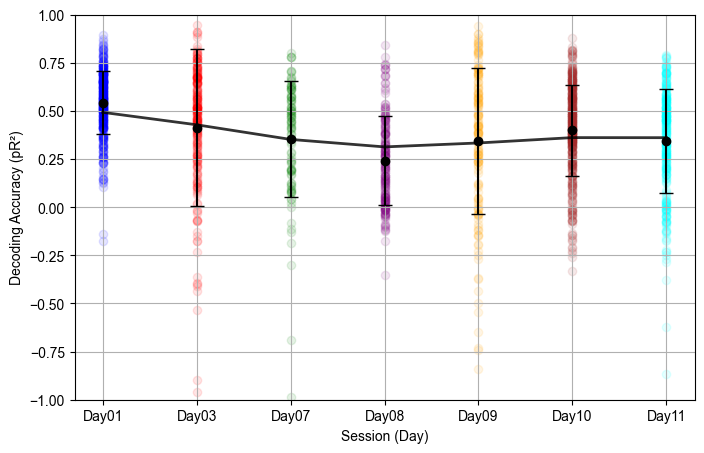

In [937]:


import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import PoissonRegressor
from scipy.ndimage import gaussian_filter1d

# === PARAMETERS ===
folder_path = '/Users/nmt121/Desktop/DATA/S4/'

bin_size_ms = 500  
history_bins = 4

# === TRIAL FILES GROUPED BY SESSION (DAY) ===


session_files = {
    "Day01": ['E3_MB04_Day01High_16.pkl', 'E3_MB04_Day01High_19.pkl', 'E3_MB04_Day01High_2.pkl',
              'E3_MB04_Day01High_24.pkl', 'E3_MB04_Day01High_26.pkl', 'E3_MB04_Day01High_30.pkl',
              'E3_MB04_Day01High_6.pkl', 'E3_MB04_Day01High_8.pkl'],
    "Day03": ['E3_MB04_Day03High_10.pkl', 'E3_MB04_Day03High_14.pkl', 'E3_MB04_Day03High_17.pkl',
              'E3_MB04_Day03High_19.pkl', 'E3_MB04_Day03High_22.pkl', 'E3_MB04_Day03High_27.pkl',
              'E3_MB04_Day03High_28.pkl', 'E3_MB04_Day03High_3.pkl', 'E3_MB04_Day03High_5.pkl',
              'E3_MB04_Day03High_8.pkl'],
    "Day07": ['E3_MB04_Day07High_15.pkl', 'E3_MB04_Day07High_29.pkl', 'E3_MB04_Day07High_6.pkl',
              'E3_MB04_Day07High_8.pkl'],
    "Day08": ['E3_MB04_Day08High_11.pkl', 'E3_MB04_Day08High_13.pkl', 'E3_MB04_Day08High_18.pkl',
              'E3_MB04_Day08High_19.pkl', 'E3_MB04_Day08High_2.pkl', 'E3_MB04_Day08High_22.pkl',
              'E3_MB04_Day08High_27.pkl', 'E3_MB04_Day08High_28.pkl', 'E3_MB04_Day08High_6.pkl',
              'E3_MB04_Day08High_9.pkl'],
    "Day09": ['E3_MB04_Day09High_1.pkl', 'E3_MB04_Day09High_19.pkl', 'E3_MB04_Day09High_24.pkl',
              'E3_MB04_Day09High_27.pkl', 'E3_MB04_Day09High_30.pkl', 'E3_MB04_Day09High_6.pkl'],
    "Day10": ['E3_MB04_Day10High_11.pkl', 'E3_MB04_Day10High_15.pkl', 'E3_MB04_Day10High_17.pkl',
              'E3_MB04_Day10High_2.pkl', 'E3_MB04_Day10High_21.pkl', 'E3_MB04_Day10High_22.pkl',
              'E3_MB04_Day10High_26.pkl', 'E3_MB04_Day10High_28.pkl', 'E3_MB04_Day10High_4.pkl',
              'E3_MB04_Day10High_9.pkl'],
    "Day11": ['E3_MB04_Day11High_10.pkl', 'E3_MB04_Day11High_14.pkl', 'E3_MB04_Day11High_16.pkl',
              'E3_MB04_Day11High_2.pkl', 'E3_MB04_Day11High_21.pkl', 'E3_MB04_Day11High_23.pkl',
              'E3_MB04_Day11High_27.pkl', 'E3_MB04_Day11High_28.pkl', 'E3_MB04_Day11High_4.pkl',
              'E3_MB04_Day11High_9.pkl']
}

# === HYPERPARAMETER GRID ===
alpha_grid = {'alpha': [0.1, 1, 10, 100]}  

# === STORE RESULTS PER SESSION ===
session_results = {}

for session, pkl_files in session_files.items():
    session_pR2 = []  # Store pR² values for the session

    for file in pkl_files:
        glm_data, data = load_and_preprocess(file, bin_size_ms)
        
        num_neurons = glm_data.shape[1]
        for target_idx in range(num_neurons):
            X, Y = create_glm_data(glm_data, history_bins, target_idx)
            
            if X is None or Y is None or np.sum(Y) <20:
                continue  

            X[np.isnan(X)] = 0  
            scaler = StandardScaler()
            X_scaled = scaler.fit_transform(X)
            
            kf = KFold(n_splits=3, shuffle=True, random_state=42)
            poisson_cv = GridSearchCV(PoissonRegressor(max_iter=1000), alpha_grid, cv=kf, scoring='neg_mean_poisson_deviance')
            poisson_cv.fit(X_scaled, Y)
            
            best_alpha = poisson_cv.best_params_['alpha']

            trial_pR2 = []
            for train_idx, val_idx in kf.split(X_scaled, Y > 0):
                X_train_cv, X_val_cv = X_scaled[train_idx], X_scaled[val_idx]
                Y_train_cv, Y_val_cv = Y[train_idx], Y[val_idx]

                if np.sum(Y_val_cv) < 5:
                    continue  

                poisson_model_cv = PoissonRegressor(alpha=best_alpha, max_iter=1000)
                poisson_model_cv.fit(X_train_cv, Y_train_cv)
                pR2_value = compute_pR2(poisson_model_cv, X_val_cv, Y_val_cv)
                trial_pR2.append(pR2_value)
            
            if len(trial_pR2) > 0:
                session_pR2.extend(trial_pR2)
    
    if len(session_pR2) > 0:
        session_results[session] = session_pR2

# === PLOT RESULTS ===
plt.figure(figsize=(8, 5))
plt.rcParams.update({'font.family': 'Arial'})

# Assign colours for sessions
session_colours = {
    "Day01": "blue",
    "Day03": "red",
    "Day07": "green",
    "Day08": "purple",
    "Day09": "orange",
    "Day10": "brown",
    "Day11": "cyan",
    "Day12": "magenta",
    "Day13": "lime",
    "Day14": "pink"
}

session_means = []
session_stds = []
session_labels = []

for idx, (session, pR2_values) in enumerate(session_results.items()):
    mean_pR2 = np.nanmean(pR2_values)
    std_pR2 = np.nanstd(pR2_values)
    
    session_means.append(mean_pR2)
    session_stds.append(std_pR2)
    session_labels.append(session)

    # Scatter plot of individual neurons
    x_positions = np.full(len(pR2_values), idx)  
    plt.scatter(x_positions, pR2_values, color=session_colours[session], alpha=0.1)
    
    # Mean ± std error bars
    plt.errorbar(idx, mean_pR2, yerr=std_pR2, fmt='o', color='black', capsize=5)

# === Gaussian Smoothing of Session Means ===
x_values = np.arange(len(session_means))
smoothed_means = gaussian_filter1d(session_means, sigma=1)
plt.plot(x_values, smoothed_means, linestyle='-', color='black', linewidth=2, alpha=0.8)

# X-axis labels
plt.xticks(range(len(session_labels)), session_labels)

# Labels and title
plt.xlabel("Session (Day)", fontname="Arial")
plt.ylabel("Decoding Accuracy (pR²)", fontname="Arial")
plt.ylim([-1,1])
plt.grid(True)

plt.show()


# # Convert session_results into a dataframe-friendly format
# session_labels = []
# pR2_values_all = []
# for session, values in session_results.items():
#     session_labels.extend([session] * len(values))
#     pR2_values_all.extend(values)

# # Create a violin plot
# sns.violinplot(x=session_labels, y=pR2_values_all, palette=session_colours, inner="quartile", linewidth=1.5)

# # Labels and title
# plt.xlabel("Session (Day)", fontname="Arial")
# plt.ylabel("Decoding Accuracy (pR²)", fontname="Arial")
# plt.ylim([-1, 1])
# plt.grid(False)

# plt.show()


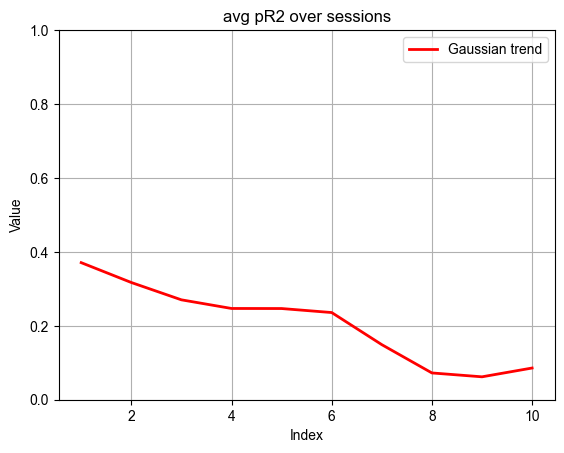

In [941]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# Data
y = np.array([0.40, 0.44, 0.24, 0.28, 0.27, 0.51, 0.31, 0.22, 0.45, 0.29, 0.46, 0.25, 0.13])
# y = np.array([0.41,0.38,.34,0.26,0.18])
y = np.array([0.42,.29,.25,.27,.16,.41,.06,.06,0.017,0.12])
# y = np.array([0.54,.37,.36,.23,0.3,.39,.31,.35,.47,.31]) #4


x = np.arange(1, len(y)+1)

# Apply Gaussian smoothing
sigma = 1  # Adjust for smoother or rougher trend
y_smooth = gaussian_filter1d(y, sigma=sigma)

# Plot scatter points
# plt.scatter(x, y, color='blue', label='Data points')

# Plot connecting line
# plt.plot(x, y, color='grey', linestyle='dashed', alpha=0.7)

# Plot Gaussian-smoothed trend
plt.plot(x, y_smooth, color='red', linewidth=2, label='Gaussian trend')

# Formatting
plt.ylim([0, 1])
plt.xlabel("Index")
plt.ylabel("Value")
plt.title("avg pR2 over sessions")
plt.legend()
plt.grid(True)

# Show plot
plt.show()


In [845]:
np.array(np.arange(1,13)).shape

(12,)

In [855]:
import zipfile
import os

# Define paths
zip_path = "/Users/nmt121/Downloads/OneDrive_2_13-03-2025.zip"
extract_folder = "/Users/nmt121/Desktop/DATA/S2/LOW"

# Ensure the output directory exists
os.makedirs(extract_folder, exist_ok=True)

# Open the zip file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    # Iterate through the files in the zip
    for file_name in zip_ref.namelist():
        # Check if "Low" is in the file name (case-sensitive)
        if "Low" in file_name:
            # Extract the matching file to the target directory
            zip_ref.extract(file_name, extract_folder)
            print(f"Extracted: {file_name}")

print("Extraction completed.")

Extracted: E3_MB02_Day13Low_15.pkl
Extracted: E3_MB02_Day13Low_1.pkl
Extracted: E3_MB02_Day13Low_10.pkl
Extracted: E3_MB02_Day13Low_20.pkl
Extracted: E3_MB02_Day13Low_4.pkl
Extracted: E3_MB02_Day13Low_16.pkl
Extracted: E3_MB02_Day13Low_25.pkl
Extracted: E3_MB02_Day13Low_7.pkl
Extracted: E3_MB02_Day13Low_30.pkl
Extracted: E3_MB02_Day13Low_22.pkl
Extracted: E3_MB02_Day03Low_20.pkl
Extracted: E3_MB02_Day02Low_18.pkl
Extracted: E3_MB02_Day02Low_13.pkl
Extracted: E3_MB02_Day02Low_19.pkl
Extracted: E3_MB02_Day02Low_10.pkl
Extracted: E3_MB02_Day02Low_27.pkl
Extracted: E3_MB02_Day02Low_3.pkl
Extracted: E3_MB02_Day02Low_24.pkl
Extracted: E3_MB02_Day02Low_4.pkl
Extracted: E3_MB02_Day03Low_2.pkl
Extracted: E3_MB02_Day03Low_16.pkl
Extracted: E3_MB02_Day03Low_14.pkl
Extracted: E3_MB02_Day03Low_12.pkl
Extracted: E3_MB02_Day02Low_30.pkl
Extracted: E3_MB02_Day02Low_7.pkl
Extracted: E3_MB02_Day04Low_6.pkl
Extracted: E3_MB02_Day04Low_28.pkl
Extracted: E3_MB02_Day04Low_19.pkl
Extracted: E3_MB02_Day04Low_

## Rasters



In [689]:
folder_path = '/Users/nmt121/Desktop/DATA/S1/LOW'
Fsamp = 2048

def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return int(match.group(1)[3:]) if match else None  # Extract numeric part of "DayXX"

def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  # Extracts numeric trial number before a non-digit
    return int(match.group(1)) if match else 0  # Default to 0 if no match found


# Sort files by (Day, Trial)
pkl_files = sorted([f for f in os.listdir(folder_path) if f.endswith('.pkl')],key=lambda x: (extract_day(x), extract_trial(x)))

num_files = len(pkl_files)
cols = 3
rows = math.ceil(num_files / cols)

fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows), sharex=False, sharey=True)
axes = axes.flatten()

for idx, file in enumerate(pkl_files):
    file_path = os.path.join(folder_path, file)

    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    data_MU = np.array(data['MU'].tolist())
    idx_pair = data['Idx_MU_Pair'].tolist()

    ax = axes[idx]

    for i in range(data_MU.shape[0]):
        spike_times = np.where(data_MU[i] == 1)[0] / Fsamp

        if i == idx_pair[0]:
            colorline = 'red'
        elif i == idx_pair[1]:
            colorline = 'blue'
        else:
            colorline = 'black'

        ax.vlines(spike_times, i + 0.5, i + 1.5, color=colorline, linewidth=0.5)

    ax.set_title(f'{file}', fontsize=10)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Neurons')

for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
# plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S7rasters.pdf', dpi=300, bbox_inches='tight')
plt.show()




## force over time plots

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_53938/2077789374.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = {day: cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}


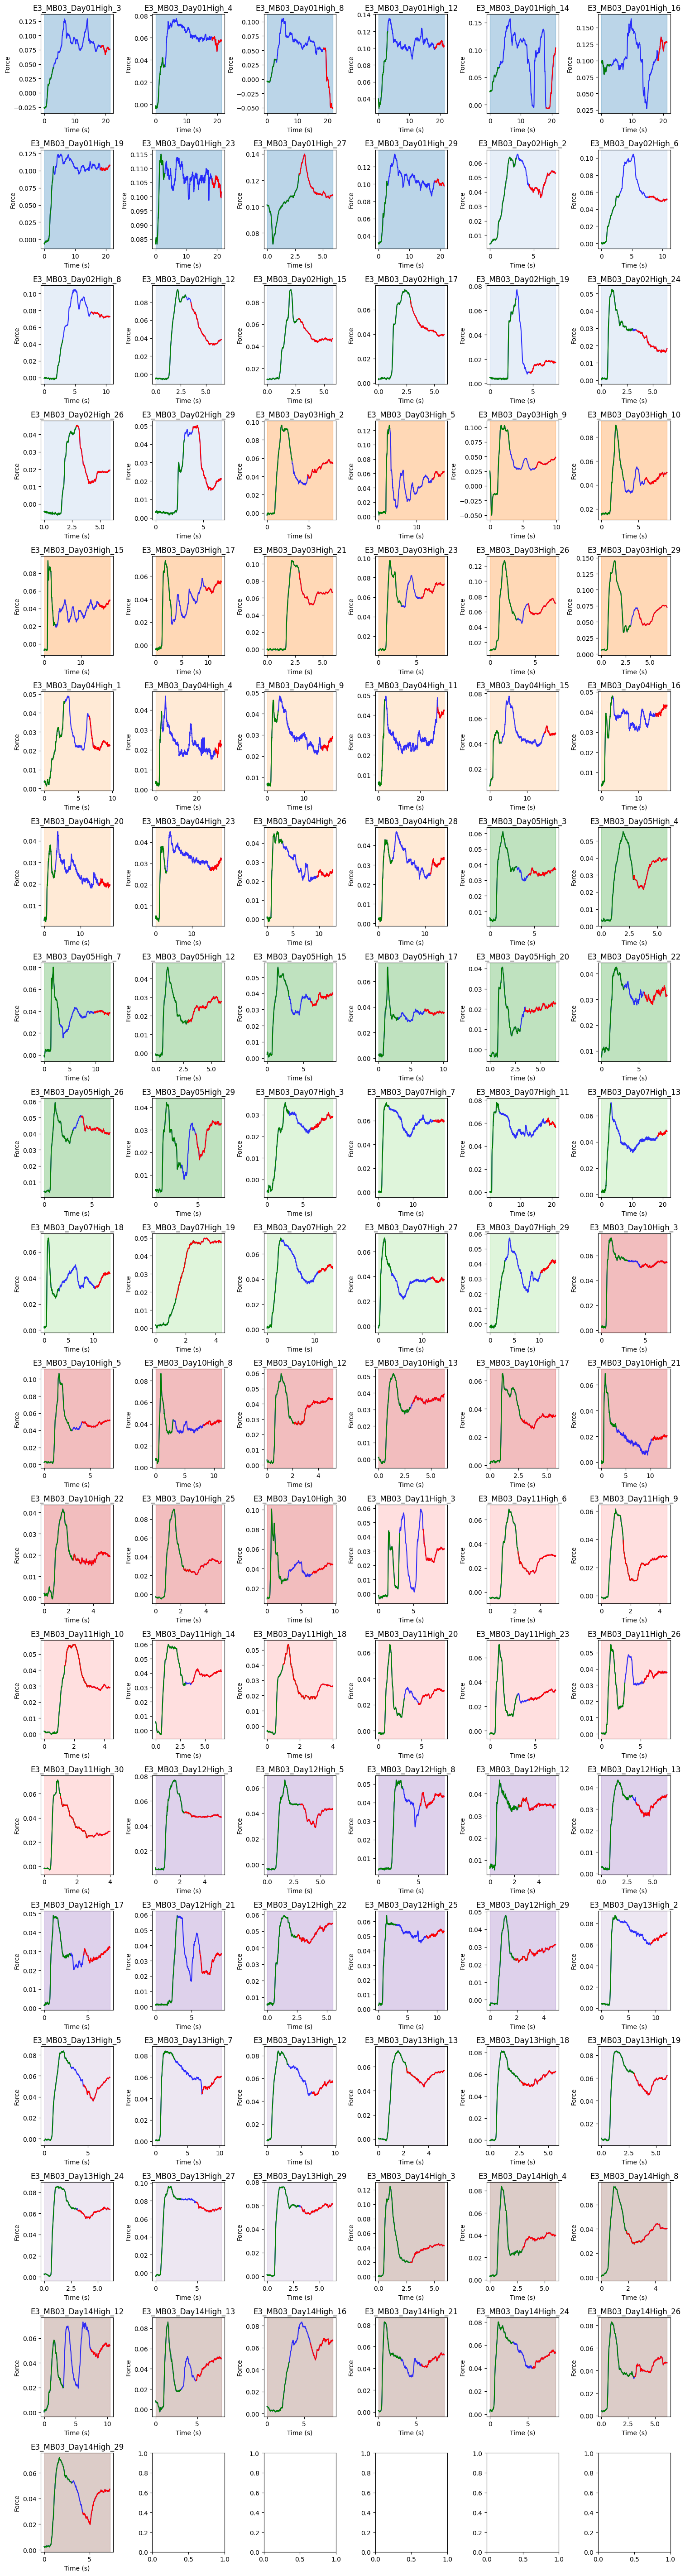

In [312]:
fsamp = 2048  
highlight_samples = int(3 * fsamp)  

directory_path = "/Users/nmt121/Desktop/DATA/S3"

# Extract day from filename
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  

# Extract trial number from filename
def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  
    return int(match.group(1)) if match else 0  

# Get all files and group by day
pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

# Create a dictionary grouping files by their respective days
files_by_day = {}
for file in pkl_files:
    day = extract_day(file)
    if day:
        if day not in files_by_day:
            files_by_day[day] = []
        files_by_day[day].append(file)

# Sort the days correctly (this was already working fine)
session_days = sorted(files_by_day.keys())

# Sort files within each day numerically
for day in session_days:
    files_by_day[day].sort(key=extract_trial)

# Flatten the sorted list to get the final ordered file list
sorted_pkl_files = [file for day in session_days for file in files_by_day[day]]

# Color mapping for each day
num_days = len(session_days)
if num_days <= 20:
    color_map = {day: cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}
else:
    color_map = {day: cm.viridis(i / num_days) for i, day in enumerate(session_days)}  

num_files = len(sorted_pkl_files)
cols = 6  
rows = int(np.ceil(num_files / cols)) 

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))
axes = axes.flatten()

for i, file_name in enumerate(sorted_pkl_files):
    file_path = os.path.join(directory_path, file_name)
    
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    data_FORCE = np.array(data['Force'].tolist())[0]  
    time_axis = np.arange(len(data_FORCE)) / fsamp  

    start_region = np.arange(highlight_samples)  
    end_region = np.arange(len(data_FORCE) - highlight_samples, len(data_FORCE))  

    day_info = extract_day(file_name)  
    day_color = color_map.get(day_info, "white")  

    idx = np.array(data['idx'].tolist()[0])
    data_MU = np.array(data['MU'].tolist())
    data_RATE = np.array(data['DR'].tolist())
    idx_pair = data['Idx_MU_Pair'].tolist()


    neuron_1 = idx_pair[0]
    neuron_2 = idx_pair[1]

    # Compute Smoothed Firing Rate
    # s1, s2 = conv_spikes(data_MU, neuron_1, neuron_2, fs=data['fsamp'])

    ax = axes[i]
    ax.plot(time_axis, data_FORCE, color="blue", alpha=0.8, label=f"{file_name}")

    ax.axvspan(time_axis[0], time_axis[-1], color=day_color, alpha=0.3, zorder=-10)

    ax.plot(time_axis[start_region], data_FORCE[start_region], color="green", alpha=1)
    ax.plot(time_axis[end_region], data_FORCE[end_region], color="red", alpha=1)

    # ax.plot(s1,s2, color="green", alpha=1)
        
    ax.set_title(file_name.split('.')[0])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Force")

plt.tight_layout()
# plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S7force.pdf', dpi=300, bbox_inches='tight')



/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_53938/625640035.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = {day: cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}


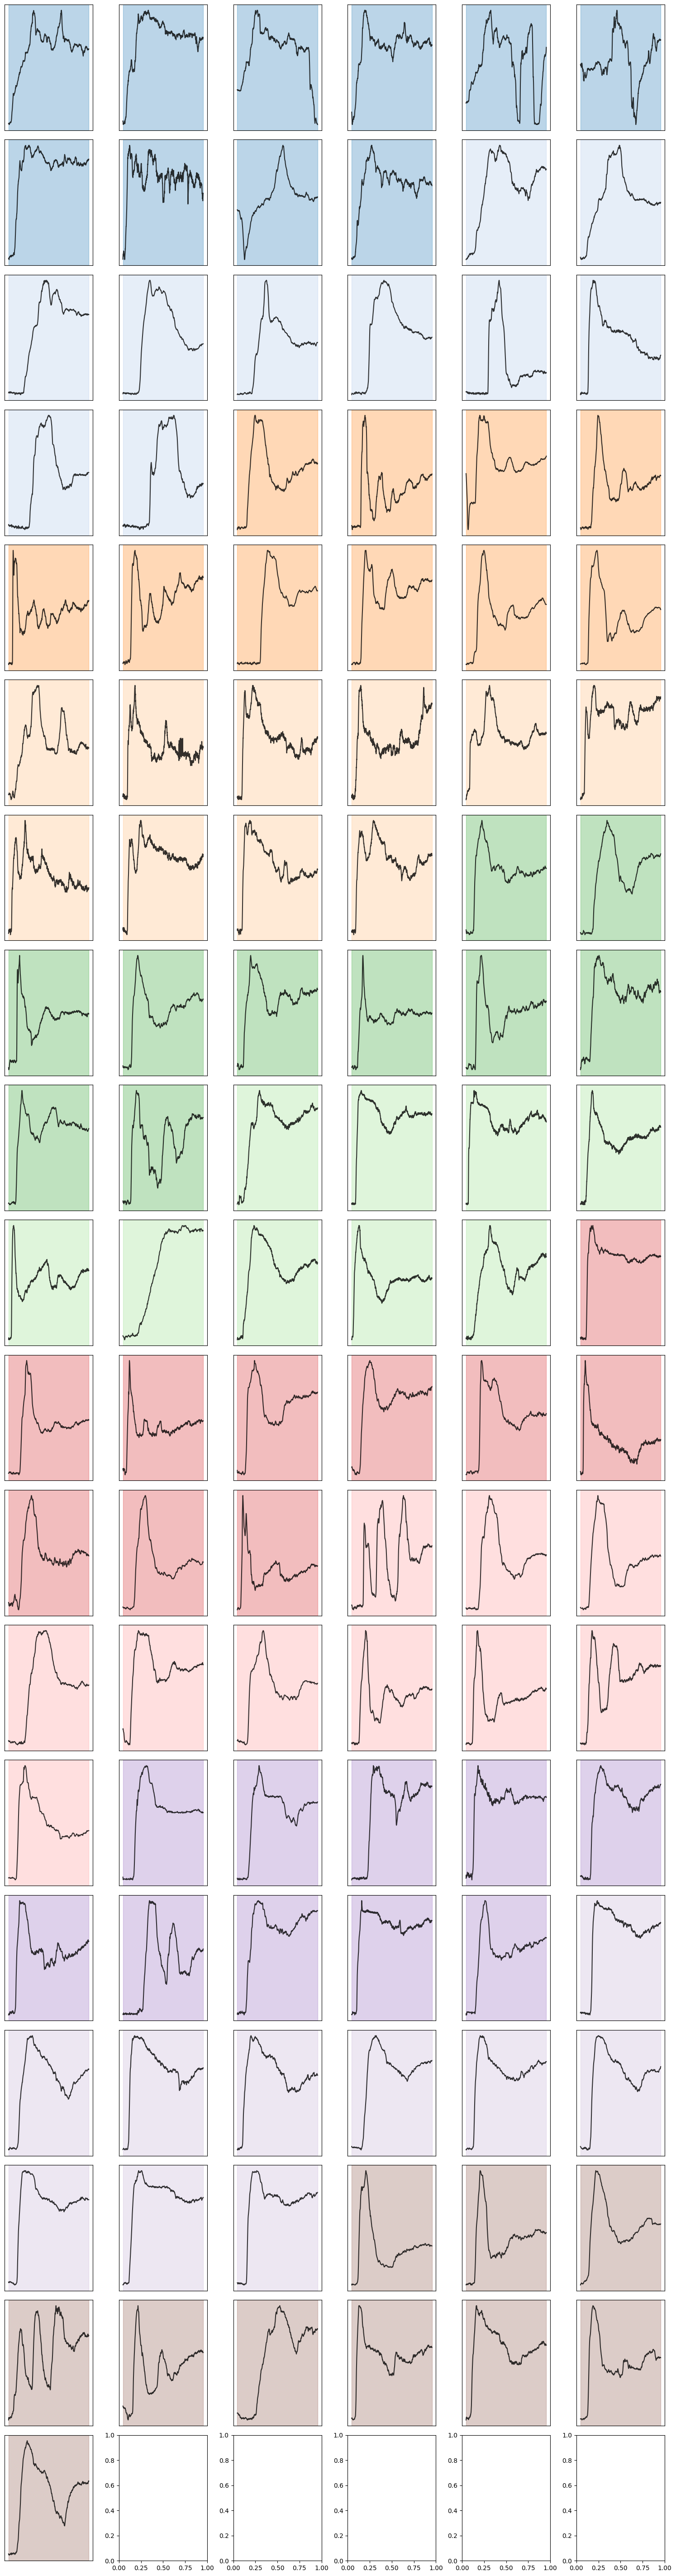

In [314]:
fsamp = 2048  
highlight_samples = int(3 * fsamp)  

directory_path = "/Users/nmt121/Desktop/DATA/S3"

# Extract day from filename
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  

# Extract trial number from filename
def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  
    return int(match.group(1)) if match else 0  

# Get all files and group by day
pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

# Create a dictionary grouping files by their respective days
files_by_day = {}
for file in pkl_files:
    day = extract_day(file)
    if day:
        if day not in files_by_day:
            files_by_day[day] = []
        files_by_day[day].append(file)

# Sort the days correctly (this was already working fine)
session_days = sorted(files_by_day.keys())

# Sort files within each day numerically
for day in session_days:
    files_by_day[day].sort(key=extract_trial)

# Flatten the sorted list to get the final ordered file list
sorted_pkl_files = [file for day in session_days for file in files_by_day[day]]

# Assign colors based on unique days
num_days = len(session_days)
if num_days <= 20:
    color_map = {day: cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}
else:
    color_map = {day: cm.viridis(i / num_days) for i, day in enumerate(session_days)}

# Plot settings
num_files = len(sorted_pkl_files)
cols = 6  
rows = int(np.ceil(num_files / cols)) 

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))
axes = axes.flatten()

# Loop through files and plot force data
for i, file_name in enumerate(sorted_pkl_files):
    file_path = os.path.join(directory_path, file_name)

    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    data_FORCE = np.array(data['Force'].tolist())[0]  
    time_axis = np.arange(len(data_FORCE)) / fsamp  

    # Extract session day info for color mapping
    day_info = extract_day(file_name)  
    day_color = color_map.get(day_info, "white")  # Default to white if not found

    # Setup plot
    ax = axes[i]

    # Apply background color per session day
    ax.axvspan(time_axis[0], time_axis[-1], color=day_color, alpha=0.3, zorder=-10)

    # Plot force data in black
    ax.plot(time_axis, data_FORCE, color="black", alpha=0.8)

    # # Remove axis ticks
    ax.set_xticks([])
    ax.set_yticks([])

    # Set title
    # ax.set_title(file_name.split('.')[0], fontsize=10)

    # Remove redundant labels
    # ax.set_xlabel("Time", fontname="Arial")
    # ax.set_ylabel("Force", fontname="Arial")
    # ax.set_xticklabels(ax.get_xticks(), fontname="Arial")
    # ax.set_yticklabels(ax.get_yticks(), fontname="Arial")

    ax.tick_params(axis='both', length=0)

# Adjust layout and save figure
plt.tight_layout()
plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S3.pdf', dpi=300, bbox_inches='tight')
plt.show()


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_53938/943121599.py:40: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = {day: cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}


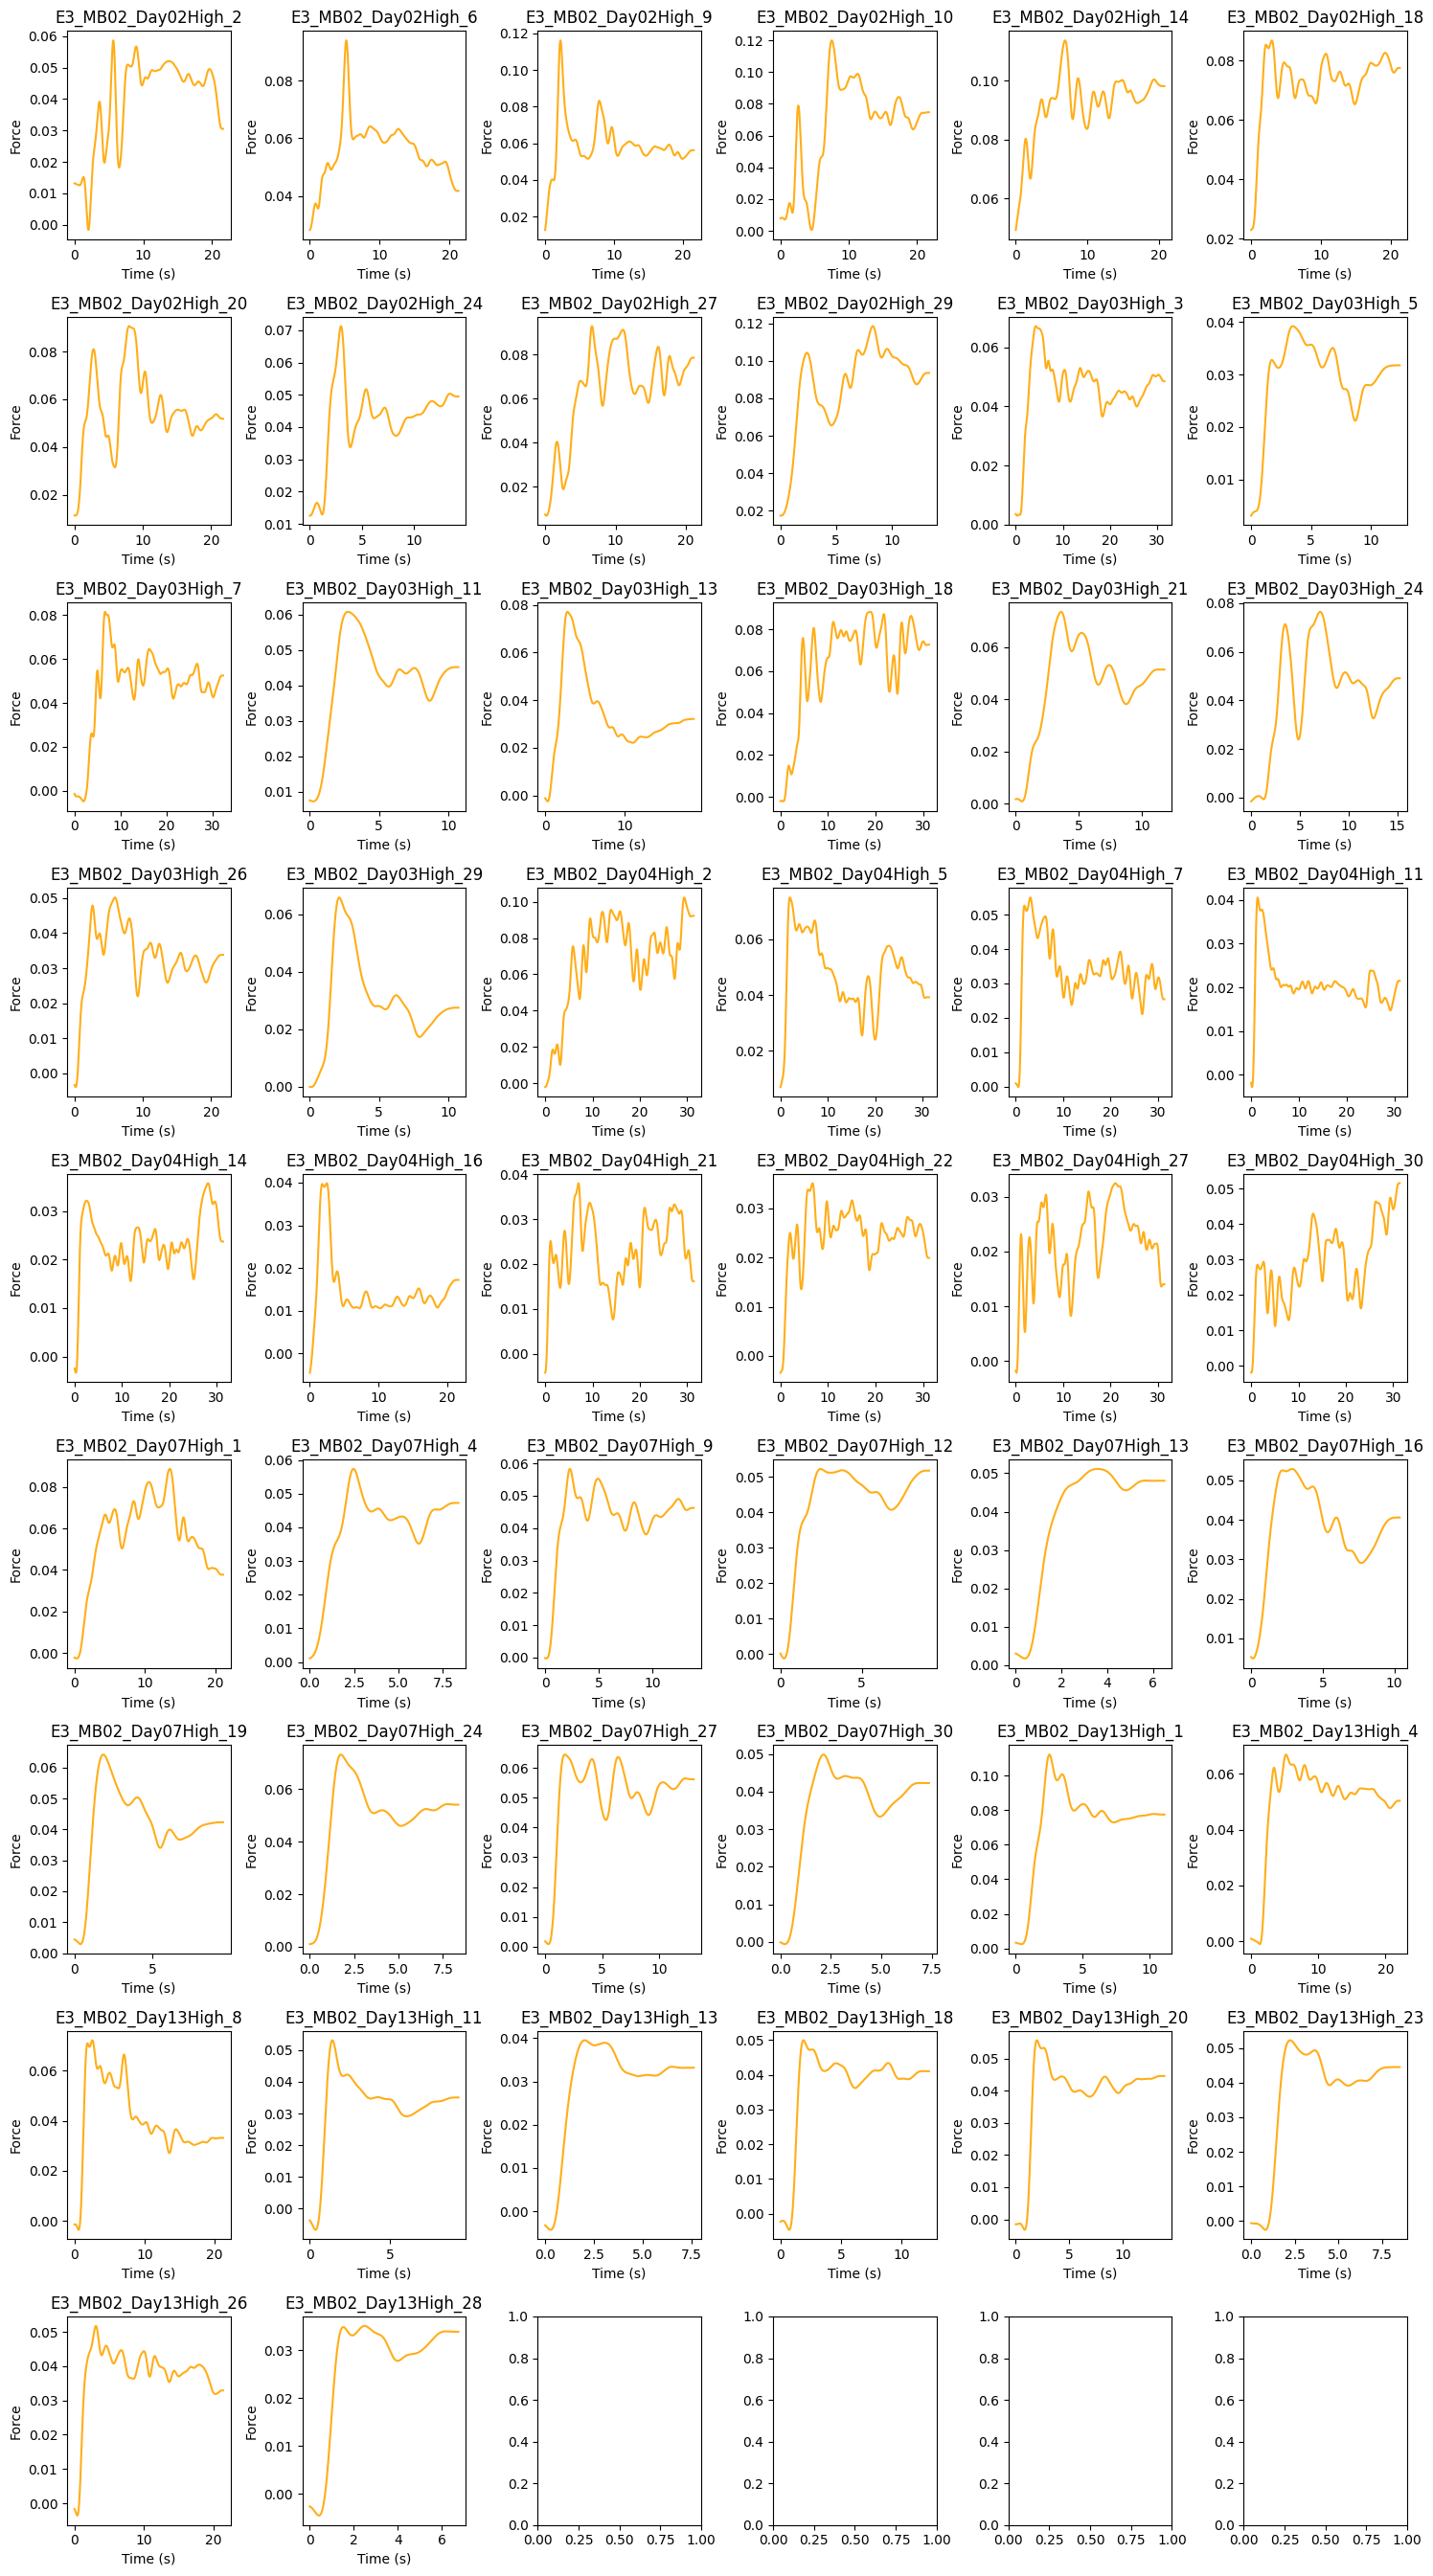

In [319]:
fsamp = 2048  
highlight_samples = int(3 * fsamp)  

directory_path = "/Users/nmt121/Desktop/DATA/S2"

# Extract day from filename
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  

# Extract trial number from filename
def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  
    return int(match.group(1)) if match else 0  

# Get all files and group by day
pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

# Create a dictionary grouping files by their respective days
files_by_day = {}
for file in pkl_files:
    day = extract_day(file)
    if day:
        if day not in files_by_day:
            files_by_day[day] = []
        files_by_day[day].append(file)

# Sort the days correctly (this was already working fine)
session_days = sorted(files_by_day.keys())

# Sort files within each day numerically
for day in session_days:
    files_by_day[day].sort(key=extract_trial)

# Flatten the sorted list to get the final ordered file list
sorted_pkl_files = [file for day in session_days for file in files_by_day[day]]

num_days = len(session_days)
if num_days <= 20:
    color_map = {day: cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}
else:
    color_map = {day: cm.viridis(i / num_days) for i, day in enumerate(session_days)}

num_files = len(sorted_pkl_files)
cols = 6  
rows = int(np.ceil(num_files / cols))  

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))
axes = axes.flatten()

# Define Low-pass filter (Butterworth)
def lowpass_filter(data, cutoff=1, fs=fsamp, order=4):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = signal.butter(order, normal_cutoff, btype='low', analog=False)
    return signal.filtfilt(b, a, data)

for i, file_name in enumerate(sorted_pkl_files):
    file_path = os.path.join(directory_path, file_name)
    
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    data_FORCE = np.array(data['Force'].tolist())[0]  
    time_axis = np.arange(len(data_FORCE)) / fsamp  

    # Apply Low-pass filter (0.5 Hz)
    filtered_force = lowpass_filter(data_FORCE)

    start_region = np.arange(highlight_samples)  
    end_region = np.arange(len(data_FORCE) - highlight_samples, len(data_FORCE))  

    ax = axes[i]
    
    # Plot raw force (blue) and filtered force (orange)
    # ax.plot(time_axis, data_FORCE, color="black", alpha=0.6, label="Raw Force")
    ax.plot(time_axis, filtered_force, color="orange", alpha=0.9, label="Filtered (0.5Hz)")

    # ax.plot(time_axis[start_region], data_FORCE[start_region], color="green", alpha=1)
    # ax.plot(time_axis[end_region], data_FORCE[end_region], color="red", alpha=1)

    ax.set_title(file_name.split('.')[0])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Force")

    # ax.legend(loc="upper right", fontsize=8)

plt.tight_layout()
# plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S7force.pdf', dpi=300, bbox_inches='tight')
plt.show()


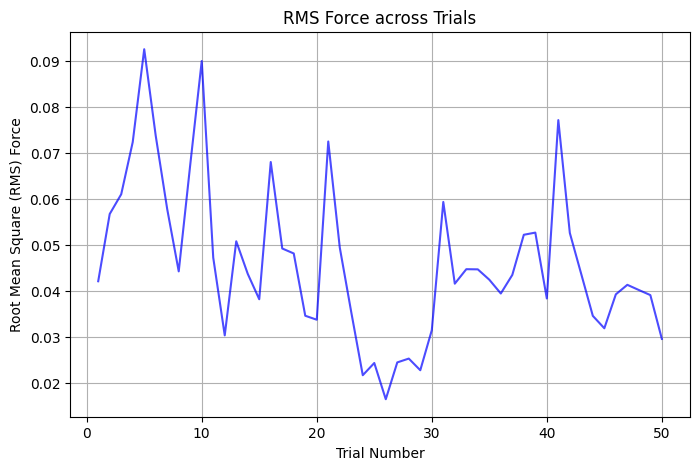

In [328]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import re

# Sampling rate
fsamp = 2048  
highlight_samples = int(3 * fsamp)  

# Directory containing the data files
directory_path = "/Users/nmt121/Desktop/DATA/S2"

# Extract day from filename
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  

# Extract trial number from filename
def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  
    return int(match.group(1)) if match else 0  

# Get all files and group by day
pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

# Create a dictionary grouping files by their respective days
files_by_day = {}
for file in pkl_files:
    day = extract_day(file)
    if day:
        if day not in files_by_day:
            files_by_day[day] = []
        files_by_day[day].append(file)

# Sort days and files within each day numerically
session_days = sorted(files_by_day.keys())
for day in session_days:
    files_by_day[day].sort(key=extract_trial)

# Flatten the sorted list to get the final ordered file list
sorted_pkl_files = [file for day in session_days for file in files_by_day[day]]

# Define Low-pass filter (Butterworth)
def lowpass_filter(data, cutoff=1, fs=fsamp, order=4):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = signal.butter(order, normal_cutoff, btype='low', analog=False)
    return signal.filtfilt(b, a, data)

# Store RMS values and trial numbers
rms_values = []
trial_numbers = []

for i, file_name in enumerate(sorted_pkl_files):
    file_path = os.path.join(directory_path, file_name)
    
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    # Extract force data
    data_FORCE = np.array(data['Force'].tolist())[0]  

    # Apply Low-pass filter (0.5 Hz)
    filtered_force = lowpass_filter(data_FORCE)

    # Compute RMS force
    rms_force = np.sqrt(np.mean(filtered_force**2))

    # Store results
    rms_values.append(rms_force)
    trial_numbers.append(i + 1)  

# Scatter plot of RMS values per trial
plt.figure(figsize=(8, 5))
plt.plot(trial_numbers, rms_values, color='b', alpha=0.7)
plt.xlabel("Trial Number")
plt.ylabel("Root Mean Square (RMS) Force")
plt.title("RMS Force across Trials")
plt.grid(True)
plt.show()


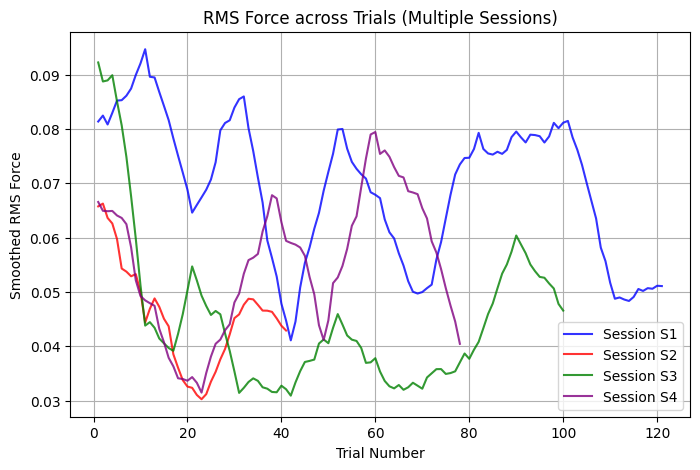

In [330]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import re

# Sampling rate
fsamp = 2048  

# Define directories to process
directory_paths = [
    "/Users/nmt121/Desktop/DATA/S1",
    "/Users/nmt121/Desktop/DATA/S2",
    "/Users/nmt121/Desktop/DATA/S3",
    "/Users/nmt121/Desktop/DATA/S4"
]

# Extract day from filename
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  

# Extract trial number from filename
def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  
    return int(match.group(1)) if match else 0  

# Define Low-pass filter (Butterworth)
def lowpass_filter(data, cutoff=1, fs=fsamp, order=4):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = signal.butter(order, normal_cutoff, btype='low', analog=False)
    return signal.filtfilt(b, a, data)

# Moving average smoothing function
def smooth_signal(data, window_size=5):
    return np.convolve(data, np.ones(window_size)/window_size, mode='valid')

# Color map for different sessions
colors = ['b', 'r', 'g', 'purple']  # Colors for S1, S2, S3, S4

# Store all RMS values
session_rms = []

# Process each session directory
for directory_path in directory_paths:
    # Get all .pkl files
    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

    # Group by day and sort numerically
    files_by_day = {}
    for file in pkl_files:
        day = extract_day(file)
        if day:
            if day not in files_by_day:
                files_by_day[day] = []
            files_by_day[day].append(file)

    # Sort days and files within each day
    session_days = sorted(files_by_day.keys())
    for day in session_days:
        files_by_day[day].sort(key=extract_trial)

    # Flatten sorted list to get ordered file list
    sorted_pkl_files = [file for day in session_days for file in files_by_day[day]]

    # Store RMS values
    rms_values = []

    for file_name in sorted_pkl_files:
        file_path = os.path.join(directory_path, file_name)
        
        with open(file_path, 'rb') as f:
            data = pickle.load(f)

        # Extract force data
        data_FORCE = np.array(data['Force'].tolist())[0]  

        # Apply Low-pass filter (0.5 Hz)
        filtered_force = lowpass_filter(data_FORCE)

        # Compute RMS force
        rms_force = np.sqrt(np.mean(filtered_force**2))

        # Store results
        rms_values.append(rms_force)

    # Apply smoothing
    rms_values = smooth_signal(rms_values, window_size=10)

    # Store session data
    session_rms.append(rms_values)

# Find the maximum trial length
max_length = max(len(rms) for rms in session_rms)

# Pad all sessions with NaNs to match max_length
session_rms_padded = [np.pad(rms, (0, max_length - len(rms)), constant_values=np.nan) for rms in session_rms]

# Convert to NumPy array for easier plotting (ignores NaNs)
session_rms_padded = np.array(session_rms_padded)

# Generate trial numbers
trial_numbers = np.arange(1, max_length + 1)

# Plot all sessions together
plt.figure(figsize=(8, 5))

for idx, rms_values in enumerate(session_rms_padded):
    plt.plot(trial_numbers, rms_values, color=colors[idx], label=f"Session S{idx+1}", alpha=0.8)

# Final plot settings
plt.xlabel("Trial Number")
plt.ylabel("Smoothed RMS Force")
plt.title("RMS Force across Trials (Multiple Sessions)")
plt.legend()
plt.grid(True)
plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/rms.pdf', dpi=300, bbox_inches='tight')

plt.show()


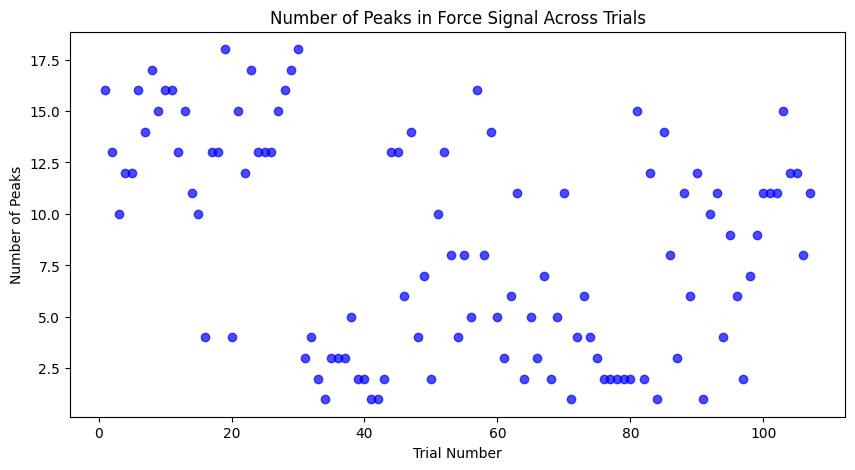

In [247]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal

# Define parameters
fsamp = 2048  # Sampling frequency
directory_path = "/Users/nmt121/Desktop/DATA/S7"

# List and sort .pkl files

# Extract day from filename
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  

# Extract trial number from filename
def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  
    return int(match.group(1)) if match else 0  

# Get all files and group by day
pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

# Create a dictionary grouping files by their respective days
files_by_day = {}
for file in pkl_files:
    day = extract_day(file)
    if day:
        if day not in files_by_day:
            files_by_day[day] = []
        files_by_day[day].append(file)

# Sort the days correctly (this was already working fine)
session_days = sorted(files_by_day.keys())

# Sort files within each day numerically
for day in session_days:
    files_by_day[day].sort(key=extract_trial)

# Flatten the sorted list to get the final ordered file list
sorted_pkl_files = [file for day in session_days for file in files_by_day[day]]



# Define a low-pass filter function
def lowpass_filter(data, cutoff=1, fs=fsamp, order=4):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = signal.butter(order, normal_cutoff, btype='low', analog=False)
    return signal.filtfilt(b, a, data)

# Store results
peak_counts = []

# Process each trial (each file is a trial)
for trial_num, file_name in enumerate(sorted_pkl_files):
    file_path = os.path.join(directory_path, file_name)
    
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    data_FORCE = np.array(data['Force'].tolist())[0]  # Extract force data
    filtered_force = lowpass_filter(data_FORCE)  # Apply low-pass filter

    # Find peaks in the filtered signal
    peaks, _ = signal.find_peaks(filtered_force)  # Adjust height threshold as needed
    num_peaks = len(peaks)

    # Store the number of peaks
    peak_counts.append(num_peaks)

# Generate trial numbers
trial_numbers = np.arange(1, len(sorted_pkl_files) + 1)

# Plot the scatter plot of peaks over trials
plt.figure(figsize=(10, 5))
plt.scatter(trial_numbers, peak_counts, alpha=0.7, color='blue')
plt.xlabel("Trial Number")
plt.ylabel("Number of Peaks")
plt.title("Number of Peaks in Force Signal Across Trials")
# plt.grid()

plt.show()


✔️ Data Shape: (54, 11)
✔️ Active Neurons: 10 / 11
Fitting GLM for neuron 1...
✅ Neuron 1: McFadden pR² = 1.000, Nagelkerke pR² = 2.054, Poisson pR² = 1.000
Fitting GLM for neuron 2...
✅ Neuron 2: McFadden pR² = 1.000, Nagelkerke pR² = 1.585, Poisson pR² = 1.000
Fitting GLM for neuron 3...
✅ Neuron 3: McFadden pR² = 1.000, Nagelkerke pR² = 4.663, Poisson pR² = 1.000
Fitting GLM for neuron 4...
✅ Neuron 4: McFadden pR² = 1.000, Nagelkerke pR² = 3.036, Poisson pR² = 1.000
Fitting GLM for neuron 5...
✅ Neuron 5: McFadden pR² = 1.000, Nagelkerke pR² = 3.399, Poisson pR² = 1.000
Fitting GLM for neuron 6...
✅ Neuron 6: McFadden pR² = 1.000, Nagelkerke pR² = 2.544, Poisson pR² = 1.000
Fitting GLM for neuron 7...
✅ Neuron 7: McFadden pR² = 1.000, Nagelkerke pR² = 6.982, Poisson pR² = 1.000
Fitting GLM for neuron 8...
✅ Neuron 8: McFadden pR² = 1.000, Nagelkerke pR² = 3.619, Poisson pR² = 1.000
Fitting GLM for neuron 9...
✅ Neuron 9: McFadden pR² = 1.000, Nagelkerke pR² = 2.389, Poisson pR² = 1

/Users/nmt121/Desktop/Repositories/Motoneuron_Model/.conda/lib/python3.12/site-packages/statsmodels/genmod/families/links.py:13: FutureWarning: The identity link alias is deprecated. Use Identity instead. The identity link alias will be removed after the 0.15.0 release.
  warnings.warn(
/Users/nmt121/Desktop/Repositories/Motoneuron_Model/.conda/lib/python3.12/site-packages/statsmodels/genmod/generalized_linear_model.py:898: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sum(resid / self.family.variance(mu)) / self.df_resid
/Users/nmt121/Desktop/Repositories/Motoneuron_Model/.conda/lib/python3.12/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/Users/nmt121/Desktop/Repositories/Motoneuron_Model/.conda/lib/python3.12/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: Perfect

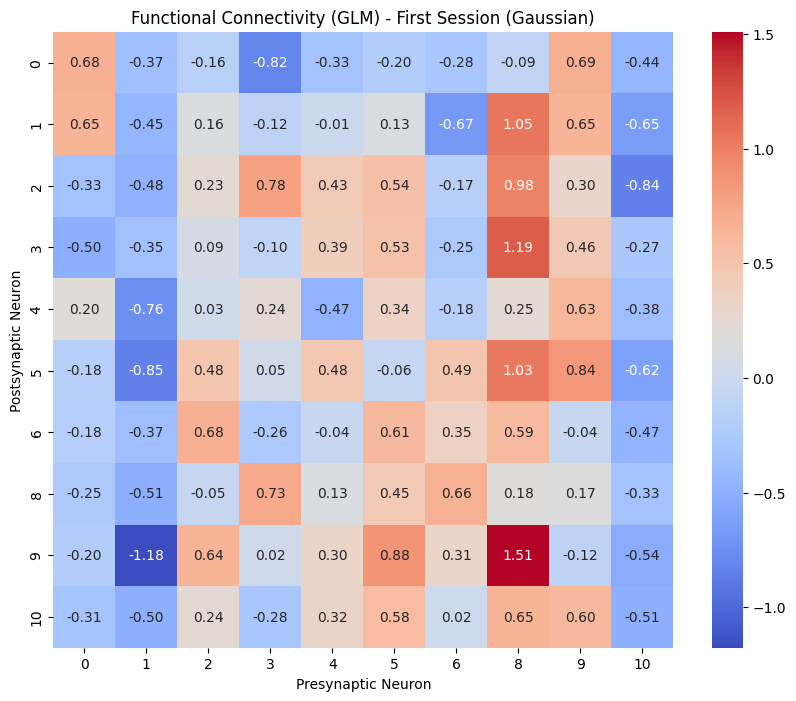

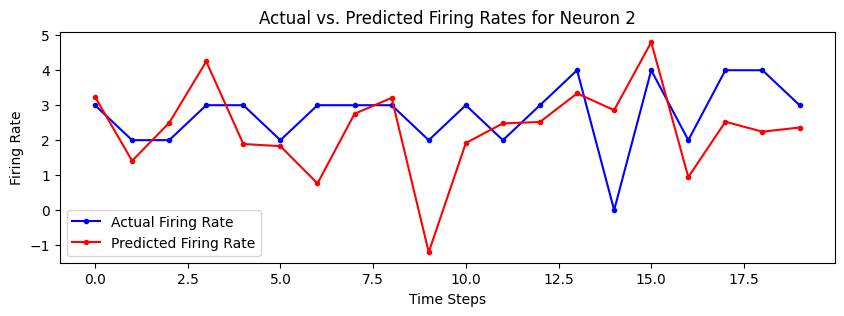

In [ ]:
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
import os
import pickle

# === PARAMETERS ===
folder_path = '/Users/nmt121/Desktop/DATA/S3'
Fsamp = 2048  
bin_size_ms = 1000 
history_bins = 5

pkl_files = sorted([f for f in os.listdir(folder_path) if f.endswith('.pkl')])
first_session_files = ['E3_MB03_Day01High_29.pkl']  # Pick one session

# === Process Data ===
all_sessions_data = []
for file in first_session_files:
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f:
        data = pickle.load(f)
    data_MU = np.array(data['MU'].tolist())  
    num_bins = data_MU.shape[1] // bin_size
    binned_spikes = np.add.reduceat(data_MU, np.arange(0, data_MU.shape[1], bin_size), axis=1)
    all_sessions_data.append(binned_spikes.T)

glm_data = np.vstack(all_sessions_data)
num_neurons = glm_data.shape[1]
print(f"✔️ Data Shape: {glm_data.shape}")

# === Exclude Inactive Neurons (All Zeros) ===
active_neurons = np.where(glm_data.sum(axis=0) > 0)[0]  # Keep only neurons with activity
glm_data = glm_data[:, active_neurons]  # Filter out inactive neurons
print(f"✔️ Active Neurons: {len(active_neurons)} / {num_neurons}")

# === CREATE DESIGN MATRIX ===
def create_glm_data(spike_data, history_bins):
    num_timebins, num_neurons = spike_data.shape
    X_list, Y_list = [], []
    for t in range(history_bins, num_timebins):
        X_t = np.hstack([spike_data[t - h] for h in range(1, history_bins + 1)])  
        Y_t = spike_data[t]  
        X_list.append(X_t)
        Y_list.append(Y_t)
    return np.array(X_list), np.array(Y_list)

X, Y = create_glm_data(glm_data, history_bins)

# === HANDLE NaNs IN X (ONLY X NEEDS IT) ===
X[np.isnan(X)] = 0  

# === TRAIN/TEST SPLIT (More Training Data) ===
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.4, random_state=42)

# === NORMALIZE FEATURES (NOT Y) ===
imputer = SimpleImputer(strategy="mean")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# === FIT GAUSSIAN GLM ===
models = []
pr2_scores = []
for neuron in range(Y.shape[1]):
    print(f"Fitting GLM for neuron {neuron + 1}...")
    X_neuron = X_train.copy()
    Y_neuron = Y_train[:, neuron]

    # Remove near-zero variance predictors
    non_constant_cols = np.where(np.std(X_neuron, axis=0) > 1e-10)[0]
    if len(non_constant_cols) == 0:
        print(f"Skipping neuron {neuron} due to all-zero predictors.")
        continue
    X_neuron = X_neuron[:, non_constant_cols]

    try:
        glm = sm.GLM(Y_neuron, X_neuron, family=sm.families.Gaussian(link=sm.families.links.identity()))
        result = glm.fit()
        models.append(result)

        # Compute Log-Likelihood Manually
        predicted_values = result.predict(X_neuron)
        LL_model = np.sum(-0.5 * ((Y_neuron - predicted_values) ** 2))  # Log-likelihood under Gaussian assumption

        # Compute Null Model (Intercept only)
        mean_rate = np.mean(Y_neuron)
        LL_null = np.sum(-0.5 * ((Y_neuron - mean_rate) ** 2))  # Log-likelihood for a null model

        # Compute McFadden’s pseudo-R²
        pr2_mcfadden = 1 - (LL_model / LL_null)

        # Compute Nagelkerke’s pseudo-R²
        N = len(Y_neuron)
        pr2_nagelkerke = pr2_mcfadden / (1 - np.exp(LL_null / N))

        # Compute Poisson pR² (deviance-based)
        deviance_model = np.sum((Y_neuron - predicted_values) ** 2)
        deviance_null = np.sum((Y_neuron - mean_rate) ** 2)
        pr2_poisson = 1 - (deviance_model / deviance_null)

        pr2_scores.append((pr2_mcfadden, pr2_nagelkerke, pr2_poisson))

        print(f"✅ Neuron {neuron + 1}: McFadden pR² = {pr2_mcfadden:.3f}, Nagelkerke pR² = {pr2_nagelkerke:.3f}, Poisson pR² = {pr2_poisson:.3f}")

    except Exception as e:
        print(f"Skipping neuron {neuron + 1} due to estimation error: {e}")

print("\n✅ GLMs trained successfully!")

# === FUNCTIONAL CONNECTIVITY HEATMAP (EXCLUDING INACTIVE NEURONS) ===
plt.figure(figsize=(10, 8))

weights_matrix = np.array([model.params for model in models if model is not None])

if weights_matrix.ndim == 2 and weights_matrix.shape[1] == len(active_neurons) * history_bins:
    connectivity_matrix = np.median(weights_matrix.reshape(len(active_neurons), history_bins, -1), axis=1)
elif weights_matrix.ndim == 1 and weights_matrix.shape[0] == len(active_neurons) * history_bins:
    connectivity_matrix = np.median(weights_matrix.reshape(history_bins, len(active_neurons)), axis=0)
else:
    print(f"⚠️ Shape mismatch: Expected ({len(active_neurons)}, {history_bins}, {len(active_neurons)}), but got {weights_matrix.shape}")
    connectivity_matrix = np.median(weights_matrix, axis=0)

sns.heatmap(connectivity_matrix, cmap='coolwarm', annot=True, fmt=".2f",
            xticklabels=active_neurons, yticklabels=active_neurons)  # Label only active neurons

plt.title("Functional Connectivity (GLM) - First Session (Gaussian)")
plt.xlabel("Presynaptic Neuron")
plt.ylabel("Postsynaptic Neuron")
plt.show()

# === COMPARE ACTUAL VS. PREDICTED FIRING RATES ===
neuron_id = 1
predicted_spikes = models[neuron_id].predict(X_test[:100])

plt.figure(figsize=(10, 3))
plt.plot(Y_test[:, neuron_id][:100], 'bo-', label="Actual Firing Rate", markersize=3)
plt.plot(predicted_spikes, 'ro-', label="Predicted Firing Rate", markersize=3)
plt.xlabel("Time Steps")
plt.ylabel("Firing Rate")
plt.title(f"Actual vs. Predicted Firing Rates for Neuron {neuron_id + 1}")
plt.legend()
plt.show()


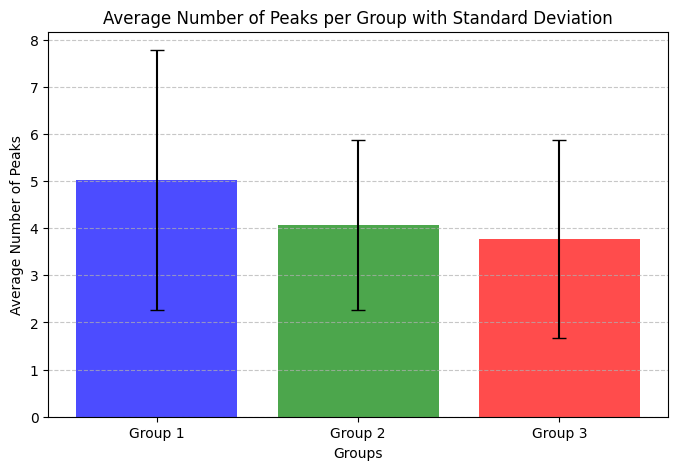

Group 1 - Avg: 5.02, Std Dev: 2.76
Group 2 - Avg: 4.07, Std Dev: 1.80
Group 3 - Avg: 3.77, Std Dev: 2.10


In [16]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal

# Define parameters
fsamp = 2048  # Sampling frequency
directory_path = "/Users/nmt121/Desktop/DATA/S1"

# List and sort .pkl files
sorted_pkl_files = sorted([f for f in os.listdir(directory_path) if f.endswith(".pkl")])

# Define a low-pass filter function
def lowpass_filter(data, cutoff=0.75, fs=fsamp, order=4):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = signal.butter(order, normal_cutoff, btype='low', analog=False)
    return signal.filtfilt(b, a, data)

# Store results
peak_counts = []

# Process each trial (each file is a trial)
for trial_num, file_name in enumerate(sorted_pkl_files):
    file_path = os.path.join(directory_path, file_name)
    
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    data_FORCE = np.array(data['Force'].tolist())[0]  # Extract force data
    filtered_force = lowpass_filter(data_FORCE)  # Apply low-pass filter

    # Find peaks in the filtered signal
    peaks, _ = signal.find_peaks(filtered_force)  # Adjust height threshold as needed
    num_peaks = len(peaks)

    # Store the number of peaks
    peak_counts.append(num_peaks)

# Generate trial numbers
trial_numbers = np.arange(1, len(sorted_pkl_files) + 1)

# Divide trials into 3 equal groups
num_trials = len(trial_numbers)
group_size = num_trials // 3

group_1 = peak_counts[:group_size]
group_2 = peak_counts[group_size:2*group_size]
group_3 = peak_counts[2*group_size:]

# Compute average number of peaks for each group
avg_group_1 = np.mean(group_1) if group_1 else 0
avg_group_2 = np.mean(group_2) if group_2 else 0
avg_group_3 = np.mean(group_3) if group_3 else 0

# Compute standard deviations for each group
std_group_1 = np.std(group_1) if group_1 else 0
std_group_2 = np.std(group_2) if group_2 else 0
std_group_3 = np.std(group_3) if group_3 else 0

# Define data for the bar plot
group_labels = ["Group 1", "Group 2", "Group 3"]
averages = [avg_group_1, avg_group_2, avg_group_3]
std_devs = [std_group_1, std_group_2, std_group_3]

# Create the bar plot
plt.figure(figsize=(8, 5))
plt.bar(group_labels, averages, yerr=std_devs, capsize=5, color=['blue', 'green', 'red'], alpha=0.7)

# Labels and title
plt.xlabel("Groups")
plt.ylabel("Average Number of Peaks")
plt.title("Average Number of Peaks per Group with Standard Deviation")
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show plot
plt.show()

# Print the averages and standard deviations
print(f"Group 1 - Avg: {avg_group_1:.2f}, Std Dev: {std_group_1:.2f}")
print(f"Group 2 - Avg: {avg_group_2:.2f}, Std Dev: {std_group_2:.2f}")
print(f"Group 3 - Avg: {avg_group_3:.2f}, Std Dev: {std_group_3:.2f}")


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_53938/2526794462.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = {day: cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}


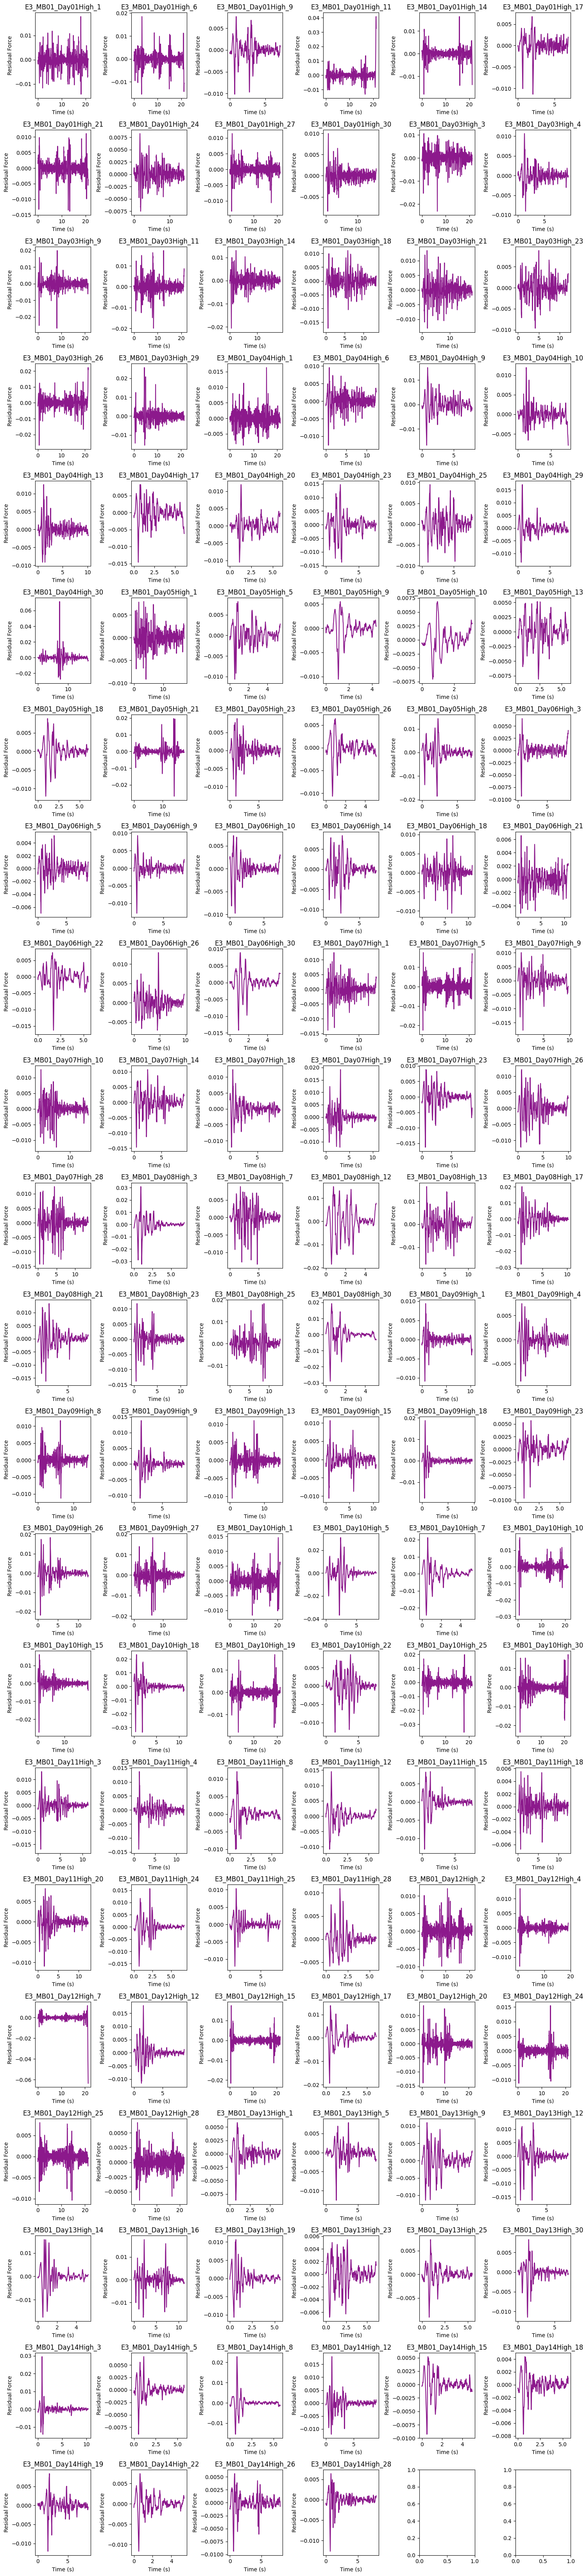

In [266]:
fsamp = 2048  
highlight_samples = int(3 * fsamp)  

directory_path = "/Users/nmt121/Desktop/DATA/S1"

# Extract day from filename
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  

# Extract trial number from filename
def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  
    return int(match.group(1)) if match else 0  

# Get all files and group by day
pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

# Create a dictionary grouping files by their respective days
files_by_day = {}
for file in pkl_files:
    day = extract_day(file)
    if day:
        if day not in files_by_day:
            files_by_day[day] = []
        files_by_day[day].append(file)

# Sort the days correctly (this was already working fine)
session_days = sorted(files_by_day.keys())

# Sort files within each day numerically
for day in session_days:
    files_by_day[day].sort(key=extract_trial)

# Flatten the sorted list to get the final ordered file list
sorted_pkl_files = [file for day in session_days for file in files_by_day[day]]


num_days = len(session_days)
if num_days <= 20:
    color_map = {day: cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}
else:
    color_map = {day: cm.viridis(i / num_days) for i, day in enumerate(session_days)}

num_files = len(sorted_pkl_files)
cols = 6  
rows = int(np.ceil(num_files / cols))  

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))
axes = axes.flatten()

# Define Low-pass filter (Butterworth)
def lowpass_filter(data, cutoff=1.5, fs=fsamp, order=4):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = signal.butter(order, normal_cutoff, btype='low', analog=False)
    return signal.filtfilt(b, a, data)

for i, file_name in enumerate(sorted_pkl_files):
    file_path = os.path.join(directory_path, file_name)
    
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    data_FORCE = np.array(data['Force'].tolist())[0]  
    time_axis = np.arange(len(data_FORCE)) / fsamp  

    # Apply Low-pass filter (1 Hz)
    filtered_force = lowpass_filter(data_FORCE)

    # Compute the force residuals (high-frequency components)
    force_residuals = data_FORCE - filtered_force

    ax = axes[i]
    
    # Plot force residuals
    ax.plot(time_axis, force_residuals, color="purple", alpha=0.9, label="Force Residuals")

    ax.set_title(file_name.split('.')[0])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Residual Force")

plt.tight_layout()
# plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S1_residuals.pdf', dpi=300, bbox_inches='tight')
plt.show()


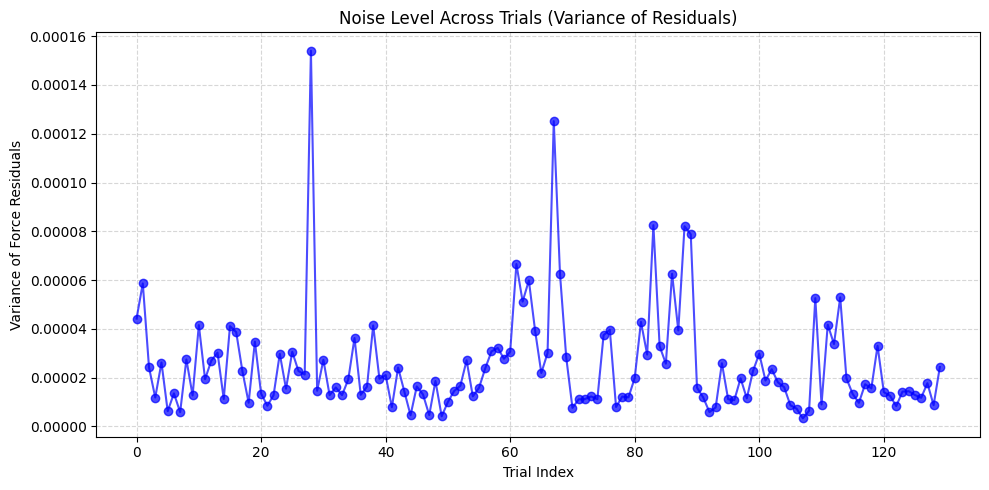

In [ ]:


fsamp = 2048  
directory_path = "/Users/nmt121/Desktop/DATA/S1"
sorted_pkl_files = sorted([f for f in os.listdir(directory_path) if f.endswith(".pkl")])


# Store variance of residuals for each trial
trial_variances = []
trial_labels = []

for file_name in sorted_pkl_files:
    file_path = os.path.join(directory_path, file_name)
    
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    data_FORCE = np.array(data['Force'].tolist())[0]  

    # Apply Low-pass filter (2 Hz)
    filtered_force = lowpass_filter(data_FORCE)

    # Compute force residuals (high-frequency components)
    force_residuals = data_FORCE - filtered_force

    # Compute variance of the residuals for this trial
    variance = np.var(force_residuals)
    
    # Store results
    trial_variances.append(variance)
    trial_labels.append(file_name.split('.')[0])  # Use filename as trial label

# Plot variance trend across trials
plt.figure(figsize=(10, 5))
plt.plot(range(len(trial_variances)), trial_variances, marker="o", linestyle="-", color="blue", alpha=0.7)

plt.xlabel("Trial Index")
plt.ylabel("Variance of Force Residuals")
plt.title("Noise Level Across Trials (Variance of Residuals)")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## trial duration

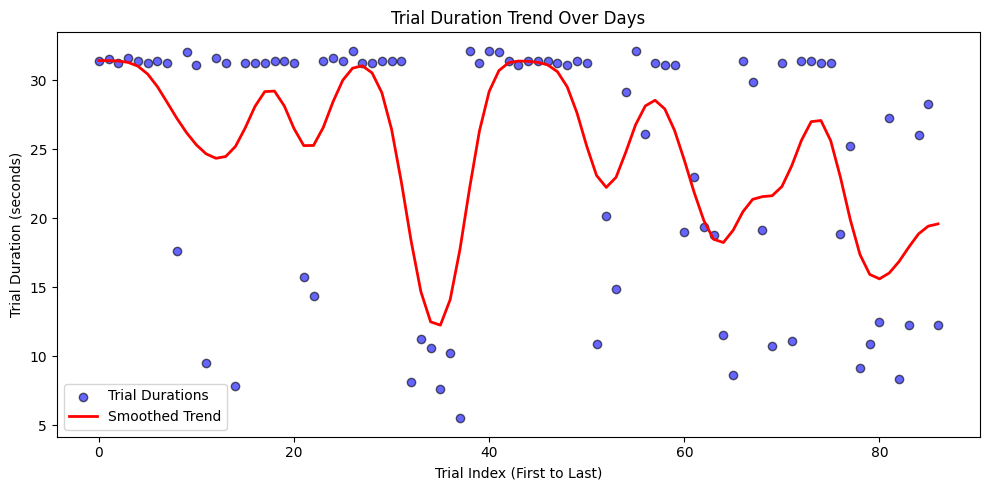

In [ ]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# Sampling frequency
fsamp = 2048  
directory_path = "/Users/nmt121/Desktop/DATA/S4"

# Get all sorted pickle files

# Extract day from filename
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  

# Extract trial number from filename
def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  
    return int(match.group(1)) if match else 0  

# Get all files and group by day
pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

# Create a dictionary grouping files by their respective days
files_by_day = {}
for file in pkl_files:
    day = extract_day(file)
    if day:
        if day not in files_by_day:
            files_by_day[day] = []
        files_by_day[day].append(file)

# Sort the days correctly (this was already working fine)
session_days = sorted(files_by_day.keys())

# Sort files within each day numerically
for day in session_days:
    files_by_day[day].sort(key=extract_trial)

# Flatten the sorted list to get the final ordered file list
sorted_pkl_files = [file for day in session_days for file in files_by_day[day]]



# Store trial durations
trial_durations = []

# Loop through files and extract trial duration
for file_name in sorted_pkl_files:
    file_path = os.path.join(directory_path, file_name)

    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    data_FORCE = np.array(data['Force'].tolist())[0]  

    # Compute trial duration (in seconds)
    trial_duration = len(data_FORCE) / fsamp  

    # Store value
    trial_durations.append(trial_duration)

# Compute a smooth trend line
smoothed_trend = gaussian_filter1d(trial_durations, sigma=2)

# Create scatter plot with trend line
plt.figure(figsize=(10, 5))
plt.scatter(range(len(trial_durations)), trial_durations, color="blue", alpha=0.6, edgecolors="black", label="Trial Durations")
plt.plot(range(len(smoothed_trend)), smoothed_trend, color="red", linewidth=2, label="Smoothed Trend")

# Format plot
plt.xlabel("Trial Index (First to Last)")
plt.ylabel("Trial Duration (seconds)")
plt.title("Trial Duration Trend Over Days")
plt.legend()
plt.grid(False)  # Remove grid

# Show plot
plt.tight_layout()
# plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/trialdur3.pdf', dpi=300, bbox_inches='tight')

plt.show()


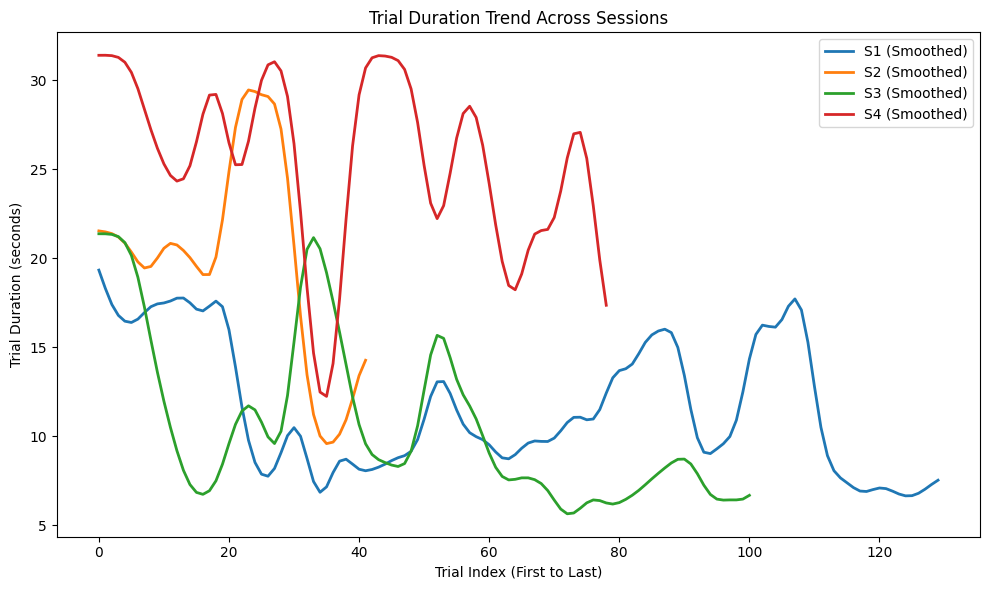

In [265]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
import pandas as pd
import re  # Ensure re module is imported

# Sampling frequency
fsamp = 2048  

# Define directory paths
directory_paths = {
    "S1": "/Users/nmt121/Desktop/DATA/S1",
    "S2": "/Users/nmt121/Desktop/DATA/S2",
    "S3": "/Users/nmt121/Desktop/DATA/S3",
    "S4": "/Users/nmt121/Desktop/DATA/S4"
}

# Extract day from filename
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  

# Extract trial number from filename
def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  
    return int(match.group(1)) if match else 0  

# Store trial durations for each session
trial_durations_dict = {}

for session, directory_path in directory_paths.items():
    if not os.path.exists(directory_path):
        print(f"⚠️ Warning: Directory {directory_path} does not exist. Skipping.")
        continue

    pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

    # Group files by day
    files_by_day = {}
    for file in pkl_files:
        day = extract_day(file)
        if day:
            if day not in files_by_day:
                files_by_day[day] = []
            files_by_day[day].append(file)

    # Sort days correctly
    session_days = sorted(files_by_day.keys())

    # Sort files within each day numerically
    for day in session_days:
        files_by_day[day].sort(key=extract_trial)

    # Flatten sorted list
    sorted_pkl_files = [file for day in session_days for file in files_by_day[day]]

    # Store trial durations
    trial_durations = []

    for file_name in sorted_pkl_files:
        file_path = os.path.join(directory_path, file_name)
        
        with open(file_path, 'rb') as f:
            data = pickle.load(f)

        data_FORCE = np.array(data['Force'].tolist())[0]  
        trial_duration = len(data_FORCE) / fsamp  # Compute trial duration in seconds
        trial_durations.append(trial_duration)

    trial_durations_dict[session] = trial_durations

# Ensure there is data before proceeding
if not trial_durations_dict:
    print("⚠️ No valid trial data found. Check your directory paths and file structure.")
else:
    # Align data with NaN padding
    max_trials = max(len(trials) for trials in trial_durations_dict.values())
    aligned_data = {session: np.pad(trials, (0, max_trials - len(trials)), constant_values=np.nan)
                    for session, trials in trial_durations_dict.items()}

    # Convert to DataFrame for plotting
    df = pd.DataFrame(aligned_data)

    # Apply Gaussian smoothing
    smoothed_data = df.apply(lambda x: gaussian_filter1d(x, sigma=2, mode='nearest'), axis=0)

    # Plot results
    plt.figure(figsize=(10, 6))

    for session in df.columns:
        # plt.scatter(range(len(df[session])), df[session], alpha=0.6, label=f"{session} (Raw)")
        plt.plot(range(len(smoothed_data[session])), smoothed_data[session], linewidth=2, label=f"{session} (Smoothed)")

    plt.xlabel("Trial Index (First to Last)")
    plt.ylabel("Trial Duration (seconds)")
    plt.title("Trial Duration Trend Across Sessions")
    plt.legend()
    plt.grid(False)
    plt.tight_layout()
    plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/trialdurfour.pdf', dpi=300, bbox_inches='tight')

    # Show the plot
    plt.show()


✔️ Data Shape: (54, 11)
✔️ Active Neurons: 11 / 11
Fitting GLM for neuron 1...
✅ Neuron 1: McFadden pR² = 1.000, Nagelkerke pR² = 1.197, Poisson pR² = 1.000
Fitting GLM for neuron 2...
✅ Neuron 2: McFadden pR² = 1.000, Nagelkerke pR² = 1.150, Poisson pR² = 1.000
Fitting GLM for neuron 3...
✅ Neuron 3: McFadden pR² = 1.000, Nagelkerke pR² = 2.597, Poisson pR² = 1.000
Fitting GLM for neuron 4...
✅ Neuron 4: McFadden pR² = 1.000, Nagelkerke pR² = 1.474, Poisson pR² = 1.000
Fitting GLM for neuron 5...
✅ Neuron 5: McFadden pR² = 1.000, Nagelkerke pR² = 1.974, Poisson pR² = 1.000
Fitting GLM for neuron 6...
✅ Neuron 6: McFadden pR² = 1.000, Nagelkerke pR² = 2.401, Poisson pR² = 1.000
Fitting GLM for neuron 7...
✅ Neuron 7: McFadden pR² = 1.000, Nagelkerke pR² = 1.936, Poisson pR² = 1.000
Fitting GLM for neuron 8...
✅ Neuron 8: McFadden pR² = 1.000, Nagelkerke pR² = 1.286, Poisson pR² = 1.000
Fitting GLM for neuron 9...
✅ Neuron 9: McFadden pR² = 1.000, Nagelkerke pR² = 2.206, Poisson pR² = 1

/Users/nmt121/Desktop/Repositories/Motoneuron_Model/.conda/lib/python3.12/site-packages/statsmodels/genmod/families/links.py:13: FutureWarning: The identity link alias is deprecated. Use Identity instead. The identity link alias will be removed after the 0.15.0 release.
  warnings.warn(
/Users/nmt121/Desktop/Repositories/Motoneuron_Model/.conda/lib/python3.12/site-packages/statsmodels/genmod/generalized_linear_model.py:898: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sum(resid / self.family.variance(mu)) / self.df_resid
/Users/nmt121/Desktop/Repositories/Motoneuron_Model/.conda/lib/python3.12/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/Users/nmt121/Desktop/Repositories/Motoneuron_Model/.conda/lib/python3.12/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: Perfect

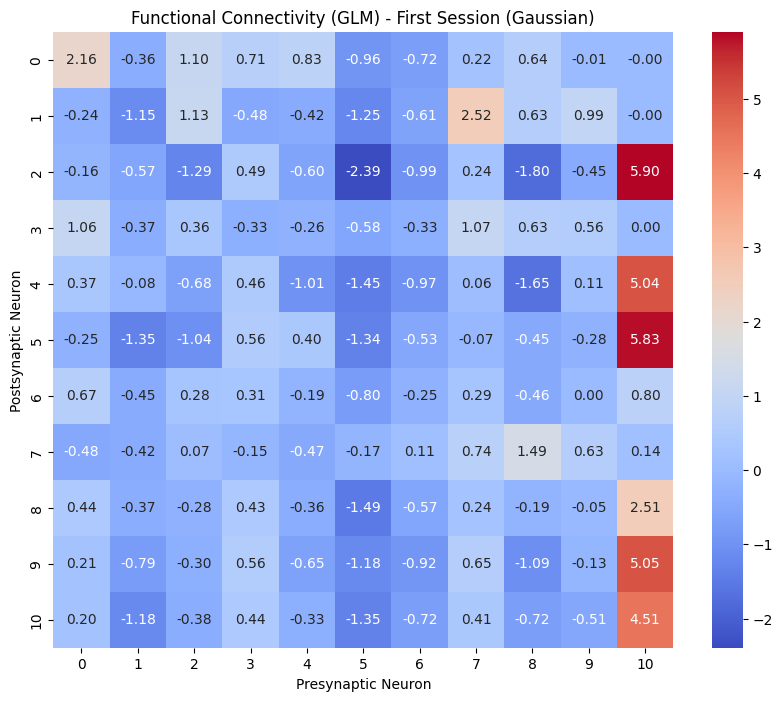

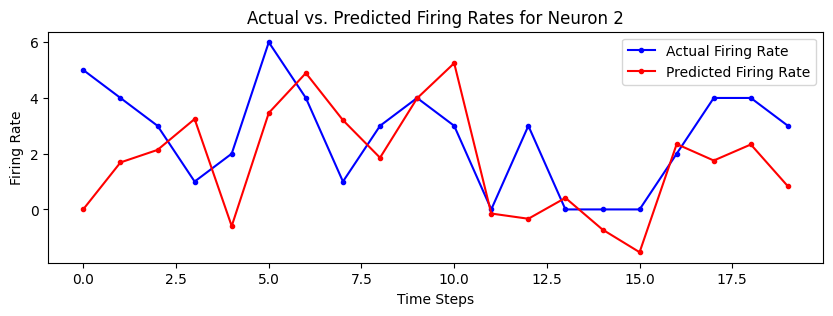

In [269]:
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
import os
import pickle

# === PARAMETERS ===
folder_path = '/Users/nmt121/Desktop/DATA/S3'
Fsamp = 2048  
bin_size_ms = 1000 
history_bins = 5

pkl_files = sorted([f for f in os.listdir(folder_path) if f.endswith('.pkl')])
first_session_files = ['E3_MB03_Day01High_3.pkl']  # Pick one session

# === Process Data ===
all_sessions_data = []
for file in first_session_files:
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f:
        data = pickle.load(f)
    data_MU = np.array(data['MU'].tolist())  
    num_bins = data_MU.shape[1] // bin_size
    binned_spikes = np.add.reduceat(data_MU, np.arange(0, data_MU.shape[1], bin_size), axis=1)
    all_sessions_data.append(binned_spikes.T)

glm_data = np.vstack(all_sessions_data)
num_neurons = glm_data.shape[1]
print(f"✔️ Data Shape: {glm_data.shape}")

# === Exclude Inactive Neurons (All Zeros) ===
active_neurons = np.where(glm_data.sum(axis=0) > 0)[0]  # Keep only neurons with activity
glm_data = glm_data[:, active_neurons]  # Filter out inactive neurons
print(f"✔️ Active Neurons: {len(active_neurons)} / {num_neurons}")

# === CREATE DESIGN MATRIX ===
def create_glm_data(spike_data, history_bins):
    num_timebins, num_neurons = spike_data.shape
    X_list, Y_list = [], []
    for t in range(history_bins, num_timebins):
        X_t = np.hstack([spike_data[t - h] for h in range(1, history_bins + 1)])  
        Y_t = spike_data[t]  
        X_list.append(X_t)
        Y_list.append(Y_t)
    return np.array(X_list), np.array(Y_list)

X, Y = create_glm_data(glm_data, history_bins)

# === HANDLE NaNs IN X (ONLY X NEEDS IT) ===
X[np.isnan(X)] = 0  

# === TRAIN/TEST SPLIT (More Training Data) ===
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.4, random_state=42)

# === NORMALIZE FEATURES (NOT Y) ===
imputer = SimpleImputer(strategy="mean")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# === FIT GAUSSIAN GLM ===
models = []
pr2_scores = []
for neuron in range(Y.shape[1]):
    print(f"Fitting GLM for neuron {neuron + 1}...")
    X_neuron = X_train.copy()
    Y_neuron = Y_train[:, neuron]

    # Remove near-zero variance predictors
    non_constant_cols = np.where(np.std(X_neuron, axis=0) > 1e-10)[0]
    if len(non_constant_cols) == 0:
        print(f"Skipping neuron {neuron} due to all-zero predictors.")
        continue
    X_neuron = X_neuron[:, non_constant_cols]

    try:
        glm = sm.GLM(Y_neuron, X_neuron, family=sm.families.Gaussian(link=sm.families.links.identity()))
        result = glm.fit()
        models.append(result)

        # Compute Log-Likelihood Manually
        predicted_values = result.predict(X_neuron)
        LL_model = np.sum(-0.5 * ((Y_neuron - predicted_values) ** 2))  # Log-likelihood under Gaussian assumption

        # Compute Null Model (Intercept only)
        mean_rate = np.mean(Y_neuron)
        LL_null = np.sum(-0.5 * ((Y_neuron - mean_rate) ** 2))  # Log-likelihood for a null model

        # Compute McFadden’s pseudo-R²
        pr2_mcfadden = 1 - (LL_model / LL_null)

        # Compute Nagelkerke’s pseudo-R²
        N = len(Y_neuron)
        pr2_nagelkerke = pr2_mcfadden / (1 - np.exp(LL_null / N))

        # Compute Poisson pR² (deviance-based)
        deviance_model = np.sum((Y_neuron - predicted_values) ** 2)
        deviance_null = np.sum((Y_neuron - mean_rate) ** 2)
        pr2_poisson = 1 - (deviance_model / deviance_null)

        pr2_scores.append((pr2_mcfadden, pr2_nagelkerke, pr2_poisson))

        print(f"✅ Neuron {neuron + 1}: McFadden pR² = {pr2_mcfadden:.3f}, Nagelkerke pR² = {pr2_nagelkerke:.3f}, Poisson pR² = {pr2_poisson:.3f}")

    except Exception as e:
        print(f"Skipping neuron {neuron + 1} due to estimation error: {e}")

print("\n✅ GLMs trained successfully!")

# === FUNCTIONAL CONNECTIVITY HEATMAP (EXCLUDING INACTIVE NEURONS) ===
plt.figure(figsize=(10, 8))

weights_matrix = np.array([model.params for model in models if model is not None])

if weights_matrix.ndim == 2 and weights_matrix.shape[1] == len(active_neurons) * history_bins:
    connectivity_matrix = np.median(weights_matrix.reshape(len(active_neurons), history_bins, -1), axis=1)
elif weights_matrix.ndim == 1 and weights_matrix.shape[0] == len(active_neurons) * history_bins:
    connectivity_matrix = np.median(weights_matrix.reshape(history_bins, len(active_neurons)), axis=0)
else:
    print(f"⚠️ Shape mismatch: Expected ({len(active_neurons)}, {history_bins}, {len(active_neurons)}), but got {weights_matrix.shape}")
    connectivity_matrix = np.median(weights_matrix, axis=0)

sns.heatmap(connectivity_matrix, cmap='coolwarm', annot=True, fmt=".2f",
            xticklabels=active_neurons, yticklabels=active_neurons)  # Label only active neurons

plt.title("Functional Connectivity (GLM) - First Session (Gaussian)")
plt.xlabel("Presynaptic Neuron")
plt.ylabel("Postsynaptic Neuron")
plt.show()

# === COMPARE ACTUAL VS. PREDICTED FIRING RATES ===
neuron_id = 1
predicted_spikes = models[neuron_id].predict(X_test[:100])

plt.figure(figsize=(10, 3))
plt.plot(Y_test[:, neuron_id][:100], 'bo-', label="Actual Firing Rate", markersize=3)
plt.plot(predicted_spikes, 'ro-', label="Predicted Firing Rate", markersize=3)
plt.xlabel("Time Steps")
plt.ylabel("Firing Rate")
plt.title(f"Actual vs. Predicted Firing Rates for Neuron {neuron_id + 1}")
plt.legend()
plt.show()


In [336]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
import os
import pickle
from pygam import PoissonGAM

# === PARAMETERS ===
folder_path = '/Users/nmt121/Desktop/DATA/S3'
Fsamp = 2048  
bin_size_ms = 1000 
history_bins = 5

pkl_files = sorted([f for f in os.listdir(folder_path) if f.endswith('.pkl')])
first_session_files = ['E3_MB03_Day01High_3.pkl']  # Pick one session

# === Process Data ===
all_sessions_data = []
for file in first_session_files:
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f:
        data = pickle.load(f)
    data_MU = np.array(data['MU'].tolist())  
    num_bins = data_MU.shape[1] // bin_size_ms
    binned_spikes = np.add.reduceat(data_MU, np.arange(0, data_MU.shape[1], bin_size_ms), axis=1)
    all_sessions_data.append(binned_spikes.T)

glm_data = np.vstack(all_sessions_data)
num_neurons = glm_data.shape[1]
print(f"✔️ Data Shape: {glm_data.shape}")

# === Exclude Inactive Neurons (All Zeros) ===
active_neurons = np.where(glm_data.sum(axis=0) > 0)[0]  # Keep only neurons with activity
glm_data = glm_data[:, active_neurons]  # Filter out inactive neurons
print(f"✔️ Active Neurons: {len(active_neurons)} / {num_neurons}")

# === CREATE DESIGN MATRIX ===
def create_glm_data(spike_data, history_bins):
    num_timebins, num_neurons = spike_data.shape
    X_list, Y_list = [], []
    for t in range(history_bins, num_timebins):
        X_t = np.hstack([spike_data[t - h] for h in range(1, history_bins + 1)])  
        Y_t = spike_data[t]  
        X_list.append(X_t)
        Y_list.append(Y_t)
    return np.array(X_list), np.array(Y_list)

X, Y = create_glm_data(glm_data, history_bins)

# === HANDLE NaNs IN X (ONLY X NEEDS IT) ===
X[np.isnan(X)] = 0  

# === TRAIN/TEST SPLIT (More Training Data) ===
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.4, random_state=42)

# === NORMALIZE FEATURES (NOT Y) ===
imputer = SimpleImputer(strategy="mean")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# === FIT GENERALIZED ADDITIVE MODEL (GAM) ===
models = []
pr2_scores = []
for neuron in range(Y.shape[1]):
    print(f"Fitting GAM for neuron {neuron + 1}...")
    X_neuron = X_train.copy()
    Y_neuron = Y_train[:, neuron]

    # Remove near-zero variance predictors
    non_constant_cols = np.where(np.std(X_neuron, axis=0) > 1e-10)[0]
    if len(non_constant_cols) == 0:
        print(f"Skipping neuron {neuron} due to all-zero predictors.")
        continue
    X_neuron = X_neuron[:, non_constant_cols]

    try:
        gam = PoissonGAM().fit(X_neuron, Y_neuron)
        models.append(gam)

        # Compute Log-Likelihood Manually
        predicted_values = gam.predict(X_neuron)
        LL_model = np.sum(Y_neuron * np.log(predicted_values + 1e-10) - predicted_values)  # Avoid log(0)

        # Compute Null Model (Intercept only)
        mean_rate = np.mean(Y_neuron)
        LL_null = np.sum(Y_neuron * np.log(mean_rate + 1e-10) - mean_rate)  # Avoid log(0)

        # Compute McFadden’s pseudo-R²
        pr2_mcfadden = 1 - (LL_model / LL_null)

        # Compute Nagelkerke’s pseudo-R²
        N = len(Y_neuron)
        pr2_nagelkerke = pr2_mcfadden / (1 - np.exp(LL_null / N))

        # Compute Poisson pR² (deviance-based)
        deviance_model = np.sum((Y_neuron - predicted_values) ** 2)
        deviance_null = np.sum((Y_neuron - mean_rate) ** 2)
        pr2_poisson = 1 - (deviance_model / deviance_null)

        pr2_scores.append((pr2_mcfadden, pr2_nagelkerke, pr2_poisson))

        print(f"✅ Neuron {neuron + 1}: McFadden pR² = {pr2_mcfadden:.3f}, Nagelkerke pR² = {pr2_nagelkerke:.3f}, Poisson pR² = {pr2_poisson:.3f}")

    except Exception as e:
        print(f"Skipping neuron {neuron + 1} due to estimation error: {e}")

print("\n✅ GAMs trained successfully!")

# === FUNCTIONAL CONNECTIVITY HEATMAP (EXCLUDING INACTIVE NEURONS) ===
plt.figure(figsize=(10, 8))

weights_matrix = np.array([model.coef_ for model in models if model is not None])

# Ensure weights_matrix is not empty
if weights_matrix.size > 0:
    try:
        expected_shape = (len(active_neurons), history_bins, -1)

        if weights_matrix.shape[1] == len(active_neurons) * history_bins:
            connectivity_matrix = np.median(weights_matrix.reshape(expected_shape), axis=1)
        elif weights_matrix.shape[0] == len(active_neurons) * history_bins:
            connectivity_matrix = np.median(weights_matrix.reshape(history_bins, len(active_neurons)), axis=0)
        else:
            print(f"⚠️ Shape mismatch: Expected {expected_shape}, but got {weights_matrix.shape}")
            connectivity_matrix = np.median(weights_matrix, axis=0)

        if connectivity_matrix.ndim == 2:  # Ensure 2D matrix before plotting
            sns.heatmap(connectivity_matrix, cmap='coolwarm', annot=True, fmt=".2f",
                        xticklabels=active_neurons, yticklabels=active_neurons)
            plt.title("Functional Connectivity (GAM) - First Session")
            plt.xlabel("Presynaptic Neuron")
            plt.ylabel("Postsynaptic Neuron")
            plt.show()
        else:
            print("⚠️ Cannot reshape into a valid 2D matrix for heatmap.")

    except Exception as e:
        print(f"⚠️ Error during reshaping: {e}")
else:
    print("⚠️ No valid weights available to compute connectivity matrix.")


# === COMPARE ACTUAL VS. PREDICTED FIRING RATES ===
neuron_id = 1
predicted_spikes = models[neuron_id].predict(X_test[:100])

plt.figure(figsize=(10, 3))
plt.plot(Y_test[:, neuron_id][:100], 'bo-', label="Actual Firing Rate", markersize=3)
plt.plot(predicted_spikes, 'ro-', label="Predicted Firing Rate", markersize=3)
plt.xlabel("Time Steps")
plt.ylabel("Firing Rate")
plt.title(f"Actual vs. Predicted Firing Rates for Neuron {neuron_id + 1}")
plt.legend()
plt.show()


✔️ Data Shape: (44, 11)
✔️ Active Neurons: 11 / 11
Fitting GAM for neuron 1...
Skipping neuron 1 due to estimation error: 'csr_matrix' object has no attribute 'A'
Fitting GAM for neuron 2...
Skipping neuron 2 due to estimation error: 'csr_matrix' object has no attribute 'A'
Fitting GAM for neuron 3...
Skipping neuron 3 due to estimation error: 'csr_matrix' object has no attribute 'A'
Fitting GAM for neuron 4...
Skipping neuron 4 due to estimation error: 'csr_matrix' object has no attribute 'A'
Fitting GAM for neuron 5...
Skipping neuron 5 due to estimation error: 'csr_matrix' object has no attribute 'A'
Fitting GAM for neuron 6...
Skipping neuron 6 due to estimation error: 'csr_matrix' object has no attribute 'A'
Fitting GAM for neuron 7...
Skipping neuron 7 due to estimation error: 'csr_matrix' object has no attribute 'A'
Fitting GAM for neuron 8...
Skipping neuron 8 due to estimation error: 'csr_matrix' object has no attribute 'A'
Fitting GAM for neuron 9...
Skipping neuron 9 due to 

IndexError: list index out of range

<Figure size 1000x800 with 0 Axes>

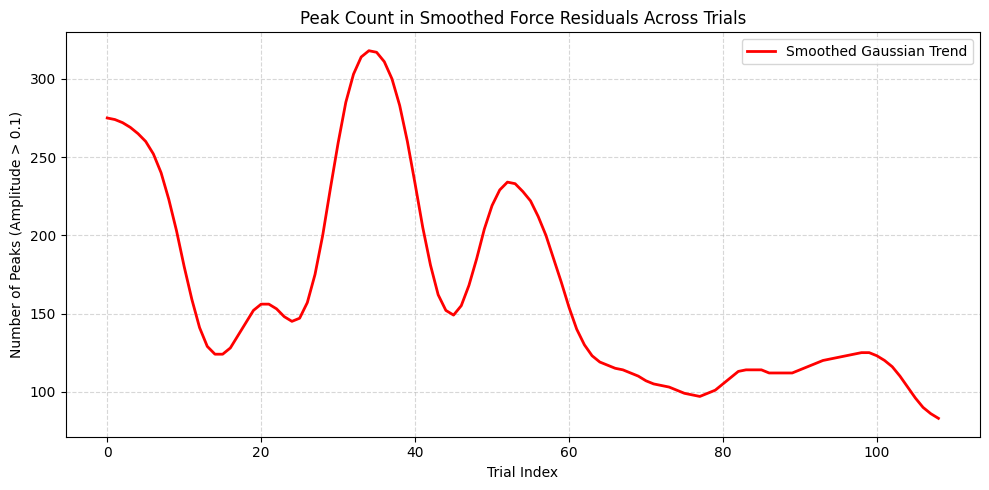

In [187]:
fsamp = 2048  
directory_path = "/Users/nmt121/Desktop/DATA/S3"

# Sort pickle files
sorted_pkl_files = sorted([f for f in os.listdir(directory_path) if f.endswith(".pkl")])


# Store peak counts for each trial
trial_peak_counts = []
trial_labels = []

for file_name in sorted_pkl_files:
    file_path = os.path.join(directory_path, file_name)
    
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    data_FORCE = np.array(data['Force'].tolist())[0]  

    filtered_force = lowpass_filter(data_FORCE)

    force_residuals = data_FORCE - filtered_force  # Compute force residuals (high-frequency components)to see fluctuations

    smoothed_residuals = gaussian_filter1d(force_residuals, sigma=1) # i want to remove tiny fluctuations

    peaks, _ = signal.find_peaks(smoothed_residuals)  

    trial_peak_counts.append(len(peaks))
    trial_labels.append(file_name.split('.')[0])  # Use filename as trial label

smoothed_peak_counts = gaussian_filter1d(trial_peak_counts, sigma=3) 

# Plot results
plt.figure(figsize=(10, 5))


# Plot Gaussian-smoothed peak trend
plt.plot(range(len(smoothed_peak_counts)), smoothed_peak_counts, linestyle="-", color="red", linewidth=2, label="Smoothed Gaussian Trend")

plt.xlabel("Trial Index")
plt.ylabel("Number of Peaks (Amplitude > 0.1)")
plt.title("Peak Count in Smoothed Force Residuals Across Trials")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
# plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S6forceresid.pdf', dpi=300, bbox_inches='tight')

plt.show()


## correlation plots

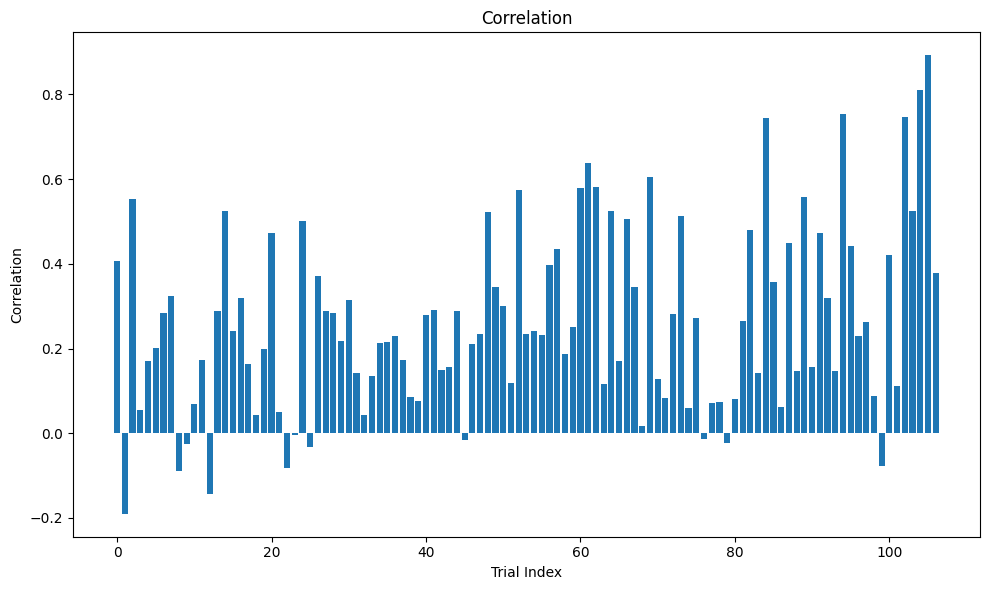

In [ ]:
fsamp = 2048  

forces = []
min_len = float('inf')

for file_name in sorted_pkl_files:
    file_path = os.path.join(directory_path, file_name)
    
    with open(file_path, 'rb') as f:
        data = pickle.load(f)
    
    force_signal = np.array(data['Force'].tolist())[0]
    forces.append(force_signal)
    
    min_len = min(min_len, len(force_signal))

downsampled_forces = [resample(force, min_len) for force in forces]

last_five_forces = downsampled_forces[-5:]
average_last_five = np.mean(last_five_forces, axis=0)

correlations = []
for force in downsampled_forces:
    corr, _ = pearsonr(force, average_last_five)
    correlations.append(corr)

plt.figure(figsize=(10, 6))
plt.bar(range(len(correlations)), correlations)
plt.xlabel('Trial Index')
plt.ylabel('Correlation')
plt.title('Correlation')
plt.tight_layout()
# plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S7correlation.pdf', dpi=300, bbox_inches='tight')
plt.show()


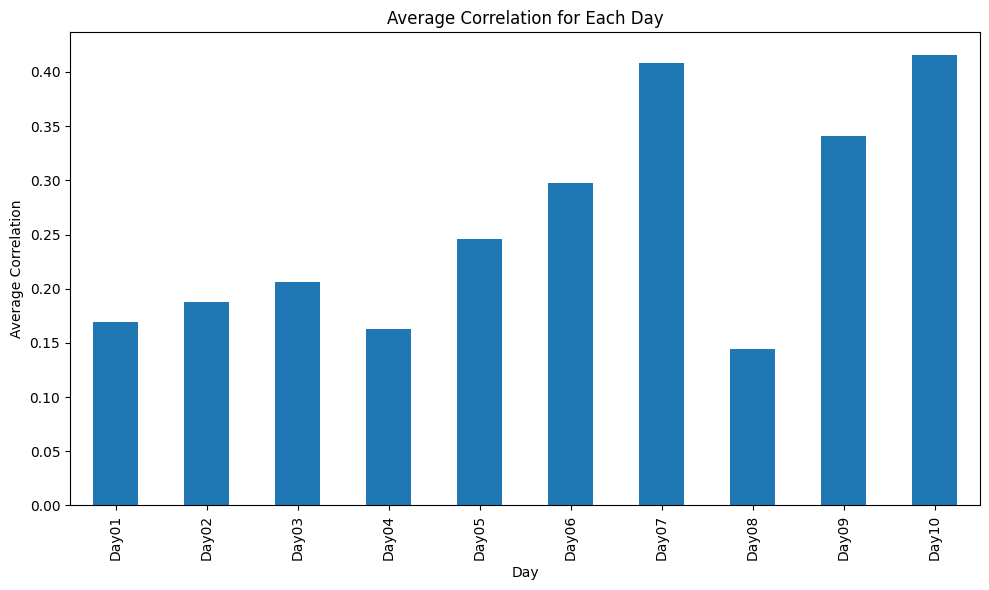

In [254]:
forces = []
min_len = float('inf')

for file_name in sorted_pkl_files:
    file_path = os.path.join(directory_path, file_name)
    
    with open(file_path, 'rb') as f:
        data = pickle.load(f)
    
    force_signal = np.array(data['Force'].tolist())[0]
    forces.append(force_signal)
    
    min_len = min(min_len, len(force_signal))

downsampled_forces = [resample(force, min_len) for force in forces]

last_five_forces = downsampled_forces[-5:]
average_last_five = np.mean(last_five_forces, axis=0)

correlations = []
for force in downsampled_forces:
    corr, _ = pearsonr(force, average_last_five)
    correlations.append(corr)

days = [re.search(r"(Day\d{2})", file).group(1) if re.search(r"(Day\d{2})", file) else None for file in sorted_pkl_files]

correlation_df = pd.DataFrame({'Trial': sorted_pkl_files,'Correlation': correlations,'Day': days})

average_correlation_per_day = correlation_df.groupby('Day')['Correlation'].mean()

average_correlation_per_day.plot(kind='bar', figsize=(10, 6))
plt.xlabel('Day')
plt.ylabel('Average Correlation')
plt.title('Average Correlation for Each Day')
plt.tight_layout()
# plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S7correlation_avg_per_session.pdf', dpi=300, bbox_inches='tight')

plt.show()


## prolongated firing MN1 switches off

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_53938/2382963712.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = {day: plt.cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}


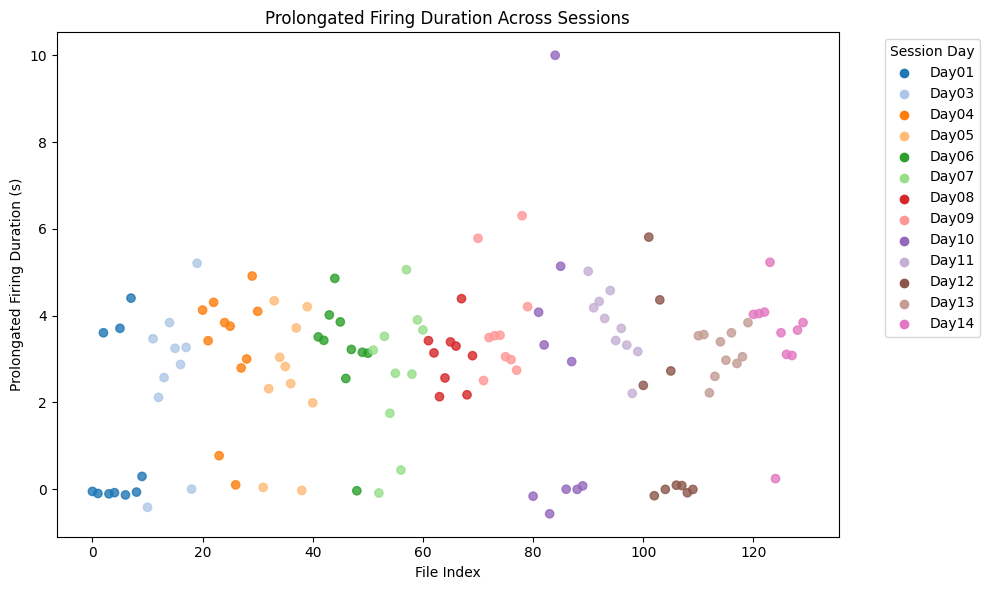

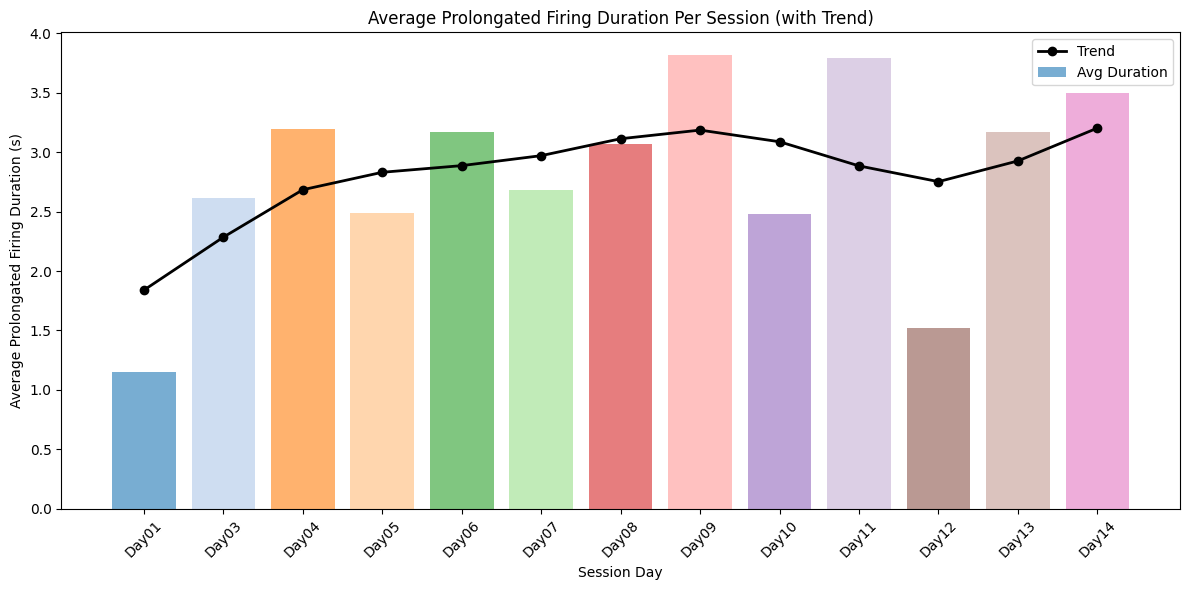

In [255]:
fsamp = 2048  
directory_path = "/Users/nmt121/Desktop/DATA/S1"

# Get all sorted pickle files

# Extract day from filename
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return match.group(1) if match else None  

# Extract trial number from filename
def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  
    return int(match.group(1)) if match else 0  

# Get all files and group by day
pkl_files = [f for f in os.listdir(directory_path) if f.endswith(".pkl")]

# Create a dictionary grouping files by their respective days
files_by_day = {}
for file in pkl_files:
    day = extract_day(file)
    if day:
        if day not in files_by_day:
            files_by_day[day] = []
        files_by_day[day].append(file)

# Sort the days correctly (this was already working fine)
session_days = sorted(files_by_day.keys())

# Sort files within each day numerically
for day in session_days:
    files_by_day[day].sort(key=extract_trial)

# Flatten the sorted list to get the final ordered file list
sorted_pkl_files = [file for day in session_days for file in files_by_day[day]]


num_days = len(session_days)  

if num_days <= 20:
    color_map = {day: plt.cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}
else:
    color_map = {day: plt.cm.viridis(i / num_days) for i, day in enumerate(session_days)}

num_files = len(sorted_pkl_files)  
total_dur = []  
colors = []  
day_durations = {day: [] for day in session_days}  

for i, file_name in enumerate(sorted_pkl_files):
    file_path = os.path.join(directory_path, file_name)  
    with open(file_path, 'rb') as f:
        data = pickle.load(f)  

    data_MU = np.array(data['MU'].tolist())  
    idx_pair = data['Idx_MU_Pair'].tolist()  

    spike_positions_small = np.where(data_MU[idx_pair[0]] == 1)[0]  
    spike_positions_large = np.where(data_MU[idx_pair[1]] == 1)[0]  

    if len(spike_positions_small) == 0 or len(spike_positions_large) == 0:
        continue  

    last_spike_position_small_mn = spike_positions_small[-1]  
    last_spike_position_large_mn = spike_positions_large[-1]  
    
    first_spike_position_small_mn = spike_positions_small[0]  
    first_spike_position_large_mn = spike_positions_large[0]  

    duration_prolongated_firing = (last_spike_position_large_mn - last_spike_position_small_mn) /fsamp #(first_spike_position_small_mn-first_spike_position_large_mn))
    total_dur.append(duration_prolongated_firing)  

    session_day = re.search(r"(Day\d{2})", file_name).group(1) if re.search(r"(Day\d{2})", file_name) else None  
    colors.append(color_map[session_day])  
    day_durations[session_day].append(duration_prolongated_firing)  

day_avg_durations = {day: np.mean(durations) for day, durations in day_durations.items() if durations}  

time = np.arange(len(total_dur))  
plt.figure(figsize=(10, 6))  
plt.scatter(time, total_dur, color=colors, alpha=0.8)  

plt.xlabel("File Index")  
plt.ylabel("Prolongated Firing Duration (s)")  
plt.title("Prolongated Firing Duration Across Sessions")  

for day, color in color_map.items():
    plt.scatter([], [], color=color, label=day)  

plt.legend(title="Session Day", bbox_to_anchor=(1.05, 1), loc='upper left')  
plt.tight_layout()  
# plt.savefig('/Users/nmt121/Desktop/figures/S1.pdf', dpi=300, bbox_inches='tight')  
plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/s3all.pdf', dpi=300, bbox_inches='tight')

plt.show()  

sorted_days = sorted(day_avg_durations.keys(), key=lambda x: int(re.search(r'\d+', x).group()))  
sorted_avg_durations = [day_avg_durations[day] for day in sorted_days]  
smoothed_avg_durations = gaussian_filter1d(sorted_avg_durations, sigma=1.2)  

plt.figure(figsize=(12, 6))  
plt.bar(sorted_days, sorted_avg_durations, color=[color_map[day] for day in sorted_days], alpha=0.6, label="Avg Duration")  
plt.plot(sorted_days, smoothed_avg_durations, marker='o', linestyle='-', color='black', linewidth=2, label="Trend")  

plt.xlabel("Session Day")  
plt.ylabel("Average Prolongated Firing Duration (s)")  
plt.title("Average Prolongated Firing Duration Per Session (with Trend)")  

plt.xticks(rotation=45)  
plt.legend()  
plt.tight_layout()  
# plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S7neuromod_metric.pdf', dpi=300, bbox_inches='tight')


plt.show()  


## force vs derivative of the force

In [250]:
# num_files = len(sorted_pkl_files)  
# cols = 6  
# rows = int(np.ceil(num_files / cols))  


# fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))  
# axes = axes.flatten()  

# for i, file_name in enumerate(sorted_pkl_files):  
#     file_path = os.path.join(directory_path, file_name)  
#     with open(file_path, 'rb') as f:  
#         data = pickle.load(f)  

#     force_signal = np.array(data['Force']).flatten()  
#     time_axis = np.arange(len(force_signal)) / fsamp  
#     force_derivative = compute_derivative(force_signal, fsamp)  

#     ax = axes[i]  
#     ax.plot(force_signal, force_derivative, color="blue", alpha=0.8)  
#     ax.set_title(file_name.split('.')[0])  
#     ax.set_xlabel("Force")  
#     ax.set_ylabel("1st Derivative of Force")  

# plt.tight_layout()  
# plt.savefig('/Users/nmt121/Desktop/RESULTS_ DATA EXP/S7derivative.pdf', dpi=300, bbox_inches='tight')

# plt.show()  